**Install Libary**

In [1]:
!pip -q install segmentation-models-pytorch==0.5.0 \
    timm==1.0.20 scipy pandas matplotlib pillow opencv-python-headless

**Hubungkan Gdive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch

print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch: 2.14.1+cu130
CUDA tersedia: True
GPU: Tesla T4


**Cari folder dataset dan chekpoint**

In [3]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

def cari_folder(nama):
    hasil = [
        p for p in DRIVE.rglob("*")
        if p.is_dir() and p.name.lower() == nama.lower()
    ]
    print(f"\nFolder '{nama}':")
    for p in hasil[:10]:
        print(" ", p)
    return hasil

zheng = cari_folder("Dataset Zheng")

assert zheng, (
    "Folder Dataset Zheng belum ditemukan. "
    "Periksa shortcut Google Drive."
)

ZHENG_ROOT = zheng[0]

dataset1 = ZHENG_ROOT / "Dataset 1"
dataset2 = ZHENG_ROOT / "Dataset 2"

assert dataset1.is_dir(), "Folder Dataset 1 tidak ditemukan"
assert dataset2.is_dir(), "Folder Dataset 2 tidak ditemukan"

checkpoint_names = [
    f"{model}_final_seed{seed}.pt"
    for model in ["unet", "deeplabv3plus"]
    for seed in [42, 43, 44]
]

checkpoint_files = {}

for p in DRIVE.rglob("*.pt"):
    if p.name in checkpoint_names:
        checkpoint_files[p.name] = p

print("\n=== CHECKPOINT ===")
for name in checkpoint_names:
    print(name, ":", checkpoint_files.get(name, "TIDAK DITEMUKAN"))

print("\n=== DATASET ===")
print("Dataset 1:", dataset1)
print("Dataset 2:", dataset2)

print("\nTotal checkpoint:", len(checkpoint_files), "/ 6")


Folder 'Dataset Zheng':
  /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/Dataset Zheng

=== CHECKPOINT ===
unet_final_seed42.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints/unet_final_seed42.pt
unet_final_seed43.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints/unet_final_seed43.pt
unet_final_seed44.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints/unet_final_seed44.pt
deeplabv3plus_final_seed42.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints (1)/deeplabv3plus_final_seed42.pt
deeplabv3plus_final_seed43.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints (1)/deeplabv3plus_final_seed43.pt
deeplabv3plus_final_seed44.pt : /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/checkpoints (1)/deeplabv3plus_final_seed44.pt

=== DATASET ===
Dataset 1: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/Dataset Zheng/Dataset 1
Dataset 2: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/Dataset Zheng/Dataset 2

Total checkpoint:

**Periksa struktur Zheng dataset 1 dan 2**

In [4]:
from collections import Counter
from PIL import Image
import numpy as np

EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def audit_dataset(root):
    print("\n" + "=" * 65)
    print("AUDIT:", root.name)
    print("=" * 65)

    files = sorted([
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in EXT
    ])

    print("Jumlah file gambar/mask:", len(files))

    folders = Counter(
        str(p.parent.relative_to(root)) for p in files
    )

    print("\nJumlah file per folder:")
    for folder, count in folders.items():
        print(f"  {folder}: {count}")

    print("\nContoh 20 file:")
    for p in files[:20]:
        print(" ", p.relative_to(root))

    print("\nInformasi 8 file pertama:")
    for p in files[:8]:
        try:
            with Image.open(p) as im:
                arr = np.asarray(im)
                print(
                    p.name,
                    "| shape:", arr.shape,
                    "| mode:", im.mode,
                    "| nilai unik:",
                    np.unique(arr)[:15]
                )
        except Exception as e:
            print("Error:", p.name, str(e))

    return files

files_d1 = audit_dataset(dataset1)
files_d2 = audit_dataset(dataset2)


AUDIT: Dataset 1
Jumlah file gambar/mask: 600

Jumlah file per folder:
  .: 600

Contoh 20 file:
  001.bmp
  001.png
  002.bmp
  002.png
  003.bmp
  003.png
  004.bmp
  004.png
  005.bmp
  005.png
  006.bmp
  006.png
  007.bmp
  007.png
  008.bmp
  008.png
  009.bmp
  009.png
  010.bmp
  010.png

Informasi 8 file pertama:
001.bmp | shape: (120, 120, 3) | mode: RGB | nilai unik: [ 0  1  3  4  6  8  9 11 13 14 16 18 19 21 23]
001.png | shape: (120, 120) | mode: L | nilai unik: [  0 128 255]
002.bmp | shape: (120, 120, 3) | mode: RGB | nilai unik: [ 0  3  4  6  8  9 11 13 14 16 18 19 21 23 24]
002.png | shape: (120, 120) | mode: L | nilai unik: [  0 128 255]
003.bmp | shape: (120, 120, 3) | mode: RGB | nilai unik: [ 0  3  4  6  8  9 11 13 14 16 18 19 21 23 24]
003.png | shape: (120, 120) | mode: L | nilai unik: [  0 128 255]
004.bmp | shape: (120, 120, 3) | mode: RGB | nilai unik: [ 0  3  4  6  8  9 11 13 16 18 19 21 23 24 26]
004.png | shape: (120, 120) | mode: L | nilai unik: [  0 128 

**Periksa isi checkpoint**

In [5]:
import torch

assert len(checkpoint_files) == 6, (
    "Belum semua 6 checkpoint ditemukan."
)

def inspect_checkpoint(path):
    print("\n" + "=" * 65)
    print("CHECKPOINT:", path.name)

    ckpt = torch.load(
        str(path),
        map_location="cpu",
        weights_only=True
    )

    print("Tipe:", type(ckpt))

    if isinstance(ckpt, dict):
        print("10 key pertama:")
        for key in list(ckpt.keys())[:10]:
            value = ckpt[key]
            if torch.is_tensor(value):
                print(" ", key, tuple(value.shape))
            else:
                print(" ", key, type(value).__name__)

        for key in ["epoch", "seed", "config", "args",
                    "model_name", "encoder_name"]:
            if key in ckpt:
                print(key, "=", ckpt[key])

    del ckpt

inspect_checkpoint(
    checkpoint_files["unet_final_seed42.pt"]
)

inspect_checkpoint(
    checkpoint_files["deeplabv3plus_final_seed42.pt"]
)


CHECKPOINT: unet_final_seed42.pt
Tipe: <class 'dict'>
10 key pertama:
  encoder.conv1.weight (64, 3, 7, 7)
  encoder.bn1.weight (64,)
  encoder.bn1.bias (64,)
  encoder.bn1.running_mean (64,)
  encoder.bn1.running_var (64,)
  encoder.bn1.num_batches_tracked ()
  encoder.layer1.0.conv1.weight (64, 64, 3, 3)
  encoder.layer1.0.bn1.weight (64,)
  encoder.layer1.0.bn1.bias (64,)
  encoder.layer1.0.bn1.running_mean (64,)

CHECKPOINT: deeplabv3plus_final_seed42.pt
Tipe: <class 'dict'>
10 key pertama:
  encoder.conv1.weight (64, 3, 7, 7)
  encoder.bn1.weight (64,)
  encoder.bn1.bias (64,)
  encoder.bn1.running_mean (64,)
  encoder.bn1.running_var (64,)
  encoder.bn1.num_batches_tracked ()
  encoder.layer1.0.conv1.weight (64, 64, 3, 3)
  encoder.layer1.0.bn1.weight (64,)
  encoder.layer1.0.bn1.bias (64,)
  encoder.layer1.0.bn1.running_mean (64,)


**Contoh gambar dan anotasi zheng**

PREVIEW ZHENG DATASET 1


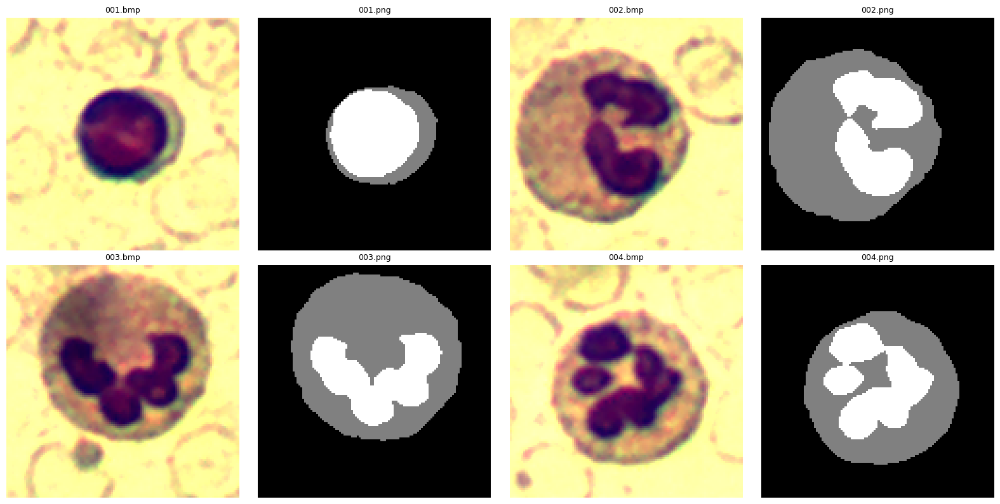

PREVIEW ZHENG DATASET 2


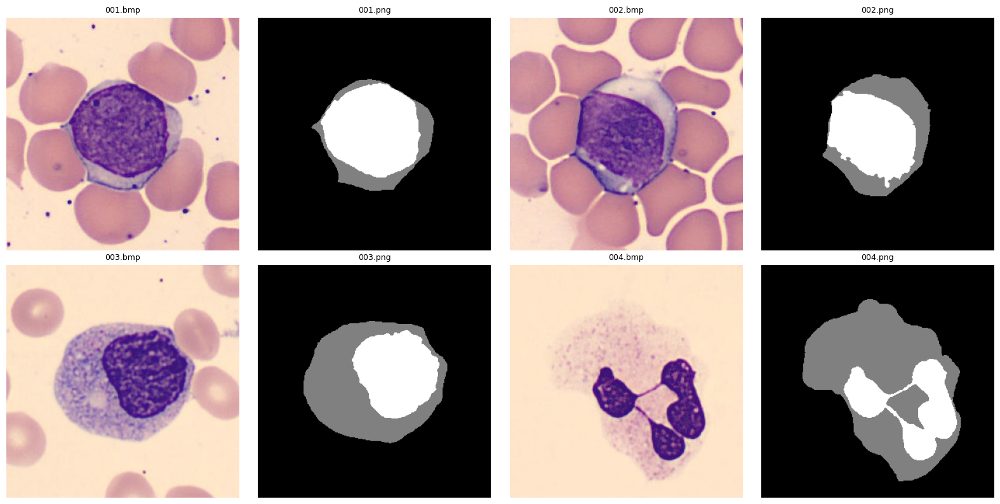

In [6]:
import matplotlib.pyplot as plt

def preview_dataset(root, files, n=8):
    if not files:
        print("Tidak ada gambar:", root)
        return

    selected = files[:n]
    fig, axes = plt.subplots(
        2, 4, figsize=(16, 8)
    )
    axes = axes.ravel()

    for ax, path in zip(axes, selected):
        img = np.asarray(Image.open(path))
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(
            str(path.relative_to(root))[:55],
            fontsize=9
        )
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("PREVIEW ZHENG DATASET 1")
preview_dataset(dataset1, files_d1)

print("PREVIEW ZHENG DATASET 2")
preview_dataset(dataset2, files_d2)

**persiapan pasangan gambar dan mask**

In [10]:
import numpy as np

MASK_VALUES = np.array([0, 128, 255], dtype=np.int16)

def convert_mask(mask):
    mask = np.asarray(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"Mask harus grayscale 2D, ditemukan {mask.shape}"
        )

    # Cari kelas dengan intensitas anotasi terdekat
    distances = np.abs(
        mask.astype(np.int16)[..., None] -
        MASK_VALUES
    )

    converted = np.argmin(
        distances,
        axis=-1
    ).astype(np.uint8)

    return converted

# Validasi semua mask
for name, pairs in [
    ("Dataset 1", pairs_d1),
    ("Dataset 2", pairs_d2)
]:
    for _, mask_path in pairs:
        mask = np.asarray(
            Image.open(mask_path).convert("L")
        )

        converted = convert_mask(mask)

        assert set(np.unique(converted)).issubset(
            {0, 1, 2}
        )

    print(f"{name}: seluruh mask valid")

print("\nKonversi mask berhasil.")

Dataset 1: seluruh mask valid
Dataset 2: seluruh mask valid

Konversi mask berhasil.


pemeriksaan mask bermasalah

In [8]:
import numpy as np
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt

VALID_VALUES = {0, 128, 255}
problem_files = []

for image_path, mask_path in pairs_d2:
    mask = np.asarray(Image.open(mask_path).convert("L"))
    values, counts = np.unique(mask, return_counts=True)

    unexpected = {
        int(v): int(c)
        for v, c in zip(values, counts)
        if int(v) not in VALID_VALUES
    }

    if unexpected:
        problem_files.append({
            "image": image_path,
            "mask": mask_path,
            "unexpected": unexpected
        })

print("Jumlah mask bermasalah:", len(problem_files))

for item in problem_files[:20]:
    print(
        item["mask"].name,
        "->", item["unexpected"]
    )

Jumlah mask bermasalah: 5
034.png -> {2: 2, 7: 38, 25: 52, 42: 1, 44: 3, 45: 1}
035.png -> {3: 3}
047.png -> {7: 179}
050.png -> {9: 22}
076.png -> {24: 1, 37: 1, 50: 1}


visualisasi mask bermasalah

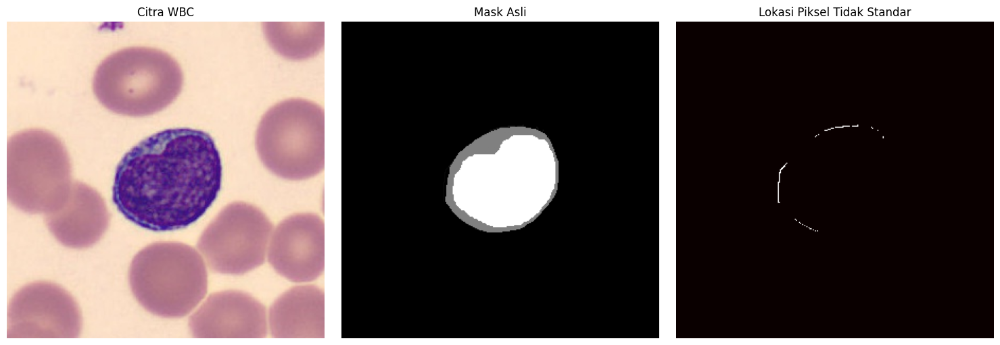

File: 034.png
Nilai tambahan: {2: 2, 7: 38, 25: 52, 42: 1, 44: 3, 45: 1}


In [9]:
if problem_files:
    item = problem_files[0]

    image = np.asarray(Image.open(item["image"]).convert("RGB"))
    mask = np.asarray(Image.open(item["mask"]).convert("L"))

    abnormal = ~np.isin(mask, [0, 128, 255])

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title("Citra WBC")

    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Mask Asli")

    axes[2].imshow(abnormal, cmap="hot")
    axes[2].set_title("Lokasi Piksel Tidak Standar")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("File:", item["mask"].name)
    print("Nilai tambahan:", item["unexpected"])
else:
    print("Tidak ada mask dengan nilai tambahan.")

**persiapkan dataloader dan preprocessing**

In [11]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

INPUT_SIZE = 256
BATCH_SIZE = 1

image_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ZhengDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = np.asarray(
            Image.open(mask_path).convert("L")
        )

        mask = convert_mask(mask)
        tensor = image_transform(image)

        return {
            "image": tensor,
            "mask": torch.from_numpy(
                mask.astype(np.int64)
            ),
            "filename": image_path.name
        }

loader_d1 = DataLoader(
    ZhengDataset(pairs_d1),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

loader_d2 = DataLoader(
    ZhengDataset(pairs_d2),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Device:", DEVICE)
print("Dataset 1:", len(loader_d1), "batch")
print("Dataset 2:", len(loader_d2), "batch")

Device: cuda
Dataset 1: 300 batch
Dataset 2: 100 batch


**buat arsitektur dan verifikasi checkpoint**

In [12]:
import segmentation_models_pytorch as smp
import gc

def build_model(model_name):
    if model_name == "unet":
        model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=3,
            classes=3
        )

    elif model_name == "deeplabv3plus":
        model = smp.DeepLabV3Plus(
            encoder_name="resnet34",
            encoder_weights=None,
            in_channels=3,
            classes=3
        )

    else:
        raise ValueError(f"Model tidak dikenal: {model_name}")

    return model

def load_model(model_name, seed):
    filename = f"{model_name}_final_seed{seed}.pt"
    path = checkpoint_files[filename]

    model = build_model(model_name)

    state = torch.load(
        str(path),
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state, strict=True)
    model = model.to(DEVICE)
    model.eval()

    return model

# Uji kompatibilitas sebelum evaluasi
for name in ["unet", "deeplabv3plus"]:
    print("\nMemeriksa:", name)

    try:
        model = load_model(name, 42)

        with torch.inference_mode():
            dummy = torch.zeros(
                1, 3, INPUT_SIZE, INPUT_SIZE,
                device=DEVICE
            )
            output = model(dummy)

        print("Checkpoint kompatibel")
        print("Output shape:", tuple(output.shape))

        del model, output, dummy
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as e:
        print("CHECKPOINT BELUM KOMPATIBEL:")
        print(str(e)[:3000])
        raise

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(



Memeriksa: unet
Checkpoint kompatibel
Output shape: (1, 3, 256, 256)

Memeriksa: deeplabv3plus
Checkpoint kompatibel
Output shape: (1, 3, 256, 256)


### **Perhitungan DIce, IoU, mloU, dan HD95**

**definisikan metrik evaluasi**

In [13]:
from scipy.ndimage import (
    binary_erosion,
    distance_transform_edt
)

def dice_iou(pred, gt, cls):
    p = pred == cls
    g = gt == cls

    intersection = np.logical_and(p, g).sum()
    total = p.sum() + g.sum()
    union = np.logical_or(p, g).sum()

    # Kedua mask kosong: kelas tersebut tidak dievaluasi
    dice = np.nan if total == 0 else (
        2.0 * intersection / total
    )
    iou = np.nan if union == 0 else (
        intersection / union
    )

    return float(dice), float(iou)

def hd95_score(pred_binary, gt_binary):
    pred_binary = pred_binary.astype(bool)
    gt_binary = gt_binary.astype(bool)

    if not pred_binary.any() and not gt_binary.any():
        return np.nan

    if not pred_binary.any() or not gt_binary.any():
        return np.nan

    p_border = pred_binary ^ binary_erosion(
        pred_binary
    )
    g_border = gt_binary ^ binary_erosion(
        gt_binary
    )

    dist_to_gt = distance_transform_edt(~g_border)
    dist_to_pred = distance_transform_edt(~p_border)

    distances = np.concatenate([
        dist_to_gt[p_border],
        dist_to_pred[g_border]
    ])

    return float(np.percentile(distances, 95))

def calculate_metrics(pred, gt):
    result = {}

    for cls, name in [(1, "cytoplasm"), (2, "nucleus")]:
        dice, iou = dice_iou(pred, gt, cls)

        p = pred == cls
        g = gt == cls

        hd = hd95_score(p, g)

        result[f"dice_{name}"] = dice
        result[f"iou_{name}"] = iou
        result[f"hd95_{name}"] = hd

        result[f"hd95_invalid_{name}"] = int(
            p.any() != g.any()
        )

    # mIoU foreground: sitoplasma dan nukleus
    result["miou"] = float(np.nanmean([
        result["iou_cytoplasm"],
        result["iou_nucleus"]
    ]))

    return result

print("Fungsi metrik siap.")

Fungsi metrik siap.


**Jalankan 1 model sebagai pengujian awal**

In [14]:
from tqdm.auto import tqdm

def evaluate_model(model, loader, dataset_name,
                   model_name, seed):
    rows = []

    model.eval()

    for batch in tqdm(
        loader,
        desc=f"{model_name} seed{seed} - {dataset_name}"
    ):
        image = batch["image"].to(DEVICE)
        gt = batch["mask"][0].numpy()
        filename = batch["filename"][0]

        with torch.inference_mode():
            logits = model(image)

            # Kembalikan prediksi ke resolusi mask asli
            logits = F.interpolate(
                logits,
                size=gt.shape,
                mode="bilinear",
                align_corners=False
            )

            pred = logits.argmax(dim=1)[0]
            pred = pred.cpu().numpy().astype(np.uint8)

        metrics = calculate_metrics(pred, gt)

        rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "seed": seed,
            "filename": filename,
            **metrics
        })

    return pd.DataFrame(rows)

model = load_model("unet", 42)

preview_loader = DataLoader(
    ZhengDataset(pairs_d1[:5]),
    batch_size=1,
    shuffle=False
)

df_preview = evaluate_model(
    model,
    preview_loader,
    "Dataset 1",
    "unet",
    42
)

display(df_preview.round(4))

del model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

unet seed42 - Dataset 1:   0%|          | 0/5 [00:00<?, ?it/s]

,dataset,model,seed,filename,dice_cytoplasm,iou_cytoplasm,hd95_cytoplasm,hd95_invalid_cytoplasm,dice_nucleus,iou_nucleus,hd95_nucleus,hd95_invalid_nucleus,miou
0,Dataset 1,unet,42,001.bmp,0.4213,0.2669,15.0200,0,0.8383,0.7217,15.8114,0,0.4943
1,Dataset 1,unet,42,002.bmp,0.4198,0.2656,20.4839,0,0.9194,0.8508,2.0000,0,0.5582
2,Dataset 1,unet,42,003.bmp,0.4434,0.2849,22.9310,0,0.9278,0.8653,2.2007,0,0.5751
3,Dataset 1,unet,42,004.bmp,0.3319,0.1989,13.4294,0,0.8950,0.8099,3.6056,0,0.5044
4,Dataset 1,unet,42,005.bmp,0.2546,0.1459,29.4109,0,0.8943,0.8088,2.8284,0,0.4773


**jalankan seluruh 12 evaluasi**

In [15]:
RESULT_DIR = (
    DRIVE / "PROYEK UAS DEEP LEARNING"
    / "results" / "external_zheng"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

datasets = {
    "Dataset 1": loader_d1,
    "Dataset 2": loader_d2
}

all_results = []

for model_name in ["unet", "deeplabv3plus"]:
    for seed in [42, 43, 44]:

        print(f"\nMODEL: {model_name} | SEED: {seed}")
        model = load_model(model_name, seed)

        for dataset_name, loader in datasets.items():

            df = evaluate_model(
                model,
                loader,
                dataset_name,
                model_name,
                seed
            )

            all_results.append(df)

            output_file = (
                RESULT_DIR /
                f"{model_name}_seed{seed}_"
                f"{dataset_name.replace(' ', '_')}.csv"
            )

            df.to_csv(output_file, index=False)
            print("Tersimpan:", output_file.name)

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

df_all = pd.concat(all_results, ignore_index=True)

df_all.to_csv(
    RESULT_DIR / "external_all_results.csv",
    index=False
)

print("\nEVALUASI SELESAI")
print("Jumlah baris:", len(df_all))
print("Folder output:", RESULT_DIR)


MODEL: unet | SEED: 42


unet seed42 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

Tersimpan: unet_seed42_Dataset_1.csv


unet seed42 - Dataset 2:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: unet_seed42_Dataset_2.csv

MODEL: unet | SEED: 43


unet seed43 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

... (15 outputs left out)

deeplabv3plus seed44 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

Tersimpan: deeplabv3plus_seed44_Dataset_1.csv


deeplabv3plus seed44 - Dataset 2:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: deeplabv3plus_seed44_Dataset_2.csv

EVALUASI SELESAI
Jumlah baris: 2400
Folder output: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng


**ringkasan rerata standar debiasi**

In [16]:
METRICS = [
    "dice_cytoplasm", "dice_nucleus",
    "iou_cytoplasm", "iou_nucleus",
    "miou",
    "hd95_cytoplasm", "hd95_nucleus"
]

# Rata-rata citra per seed
per_seed = (
    df_all.groupby(["dataset", "model", "seed"])[METRICS]
    .mean()
    .reset_index()
)

per_seed.to_csv(
    RESULT_DIR / "external_per_seed.csv",
    index=False
)

# Rata-rata dan SD antar tiga seed
summary = (
    per_seed.groupby(["dataset", "model"])[METRICS]
    .agg(["mean", "std"])
)

formatted = pd.DataFrame(index=summary.index)

for metric in METRICS:
    formatted[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            summary[(metric, "mean")],
            summary[(metric, "std")]
        )
    ]

display(formatted)

formatted.to_csv(
    RESULT_DIR / "external_summary.csv"
)

# Catat kasus HD95 tidak terdefinisi
invalid_counts = (
    df_all.groupby(["dataset", "model", "seed"])[[
        "hd95_invalid_cytoplasm",
        "hd95_invalid_nucleus"
    ]]
    .sum()
)

display(invalid_counts)
invalid_counts.to_csv(
    RESULT_DIR / "hd95_invalid_counts.csv"
)

dice_cytoplasm     dice_nucleus    iou_cytoplasm  \
dataset   model                                                              
Dataset 1 deeplabv3plus  0.6387 ± 0.0975  0.8360 ± 0.0342  0.5176 ± 0.0936   
          unet           0.6541 ± 0.0301  0.8324 ± 0.0120  0.5376 ± 0.0312   
Dataset 2 deeplabv3plus  0.8841 ± 0.0099  0.9381 ± 0.0098  0.8067 ± 0.0117   
          unet           0.8732 ± 0.0230  0.9346 ± 0.0301  0.7950 ± 0.0292   

                             iou_nucleus             miou    hd95_cytoplasm  \
dataset   model                                                               
Dataset 1 deeplabv3plus  0.7499 ± 0.0484  0.6337 ± 0.0553  10.4267 ± 2.0070   
          unet           0.7476 ± 0.0102  0.6426 ± 0.0115   9.6077 ± 0.8652   
Dataset 2 deeplabv3plus  0.8901 ± 0.0149  0.8484 ± 0.0133  12.6861 ± 1.4991   
          unet           0.8868 ± 0.0445  0.8409 ± 0.0369  14.4456 ± 2.6605   

                             hd95_nucleus  
dataset   model                            
Dataset 1 deeplabv3plus   7.4671 ± 0.6562  
          unet            7.7009 ± 0.1341  
Dataset 2 deeplabv3plus  16.8020 ± 1.5178  
          unet           17.0803 ± 2.1724

hd95_invalid_cytoplasm  hd95_invalid_nucleus
dataset   model         seed                                              
Dataset 1 deeplabv3plus 42                         0                     1
                        43                         0                     0
                        44                         0                     1
          unet          42                         0                     0
                        43                         0                     1
                        44                         0                     1
Dataset 2 deeplabv3plus 42                         0                     0
                        43                         0                     0
                        44                         0                     0
          unet          42                         0                     0
                        43                         0                     0
                        44                         0                     0

**grafik perbandingan Dice**

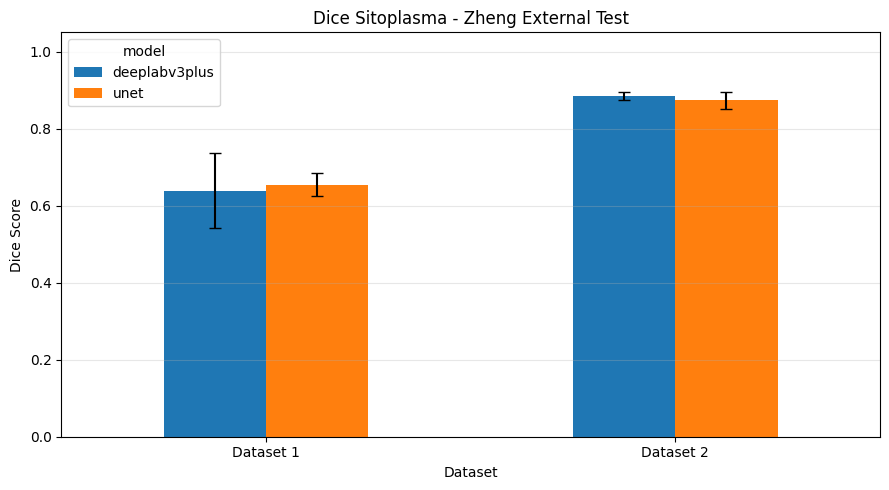

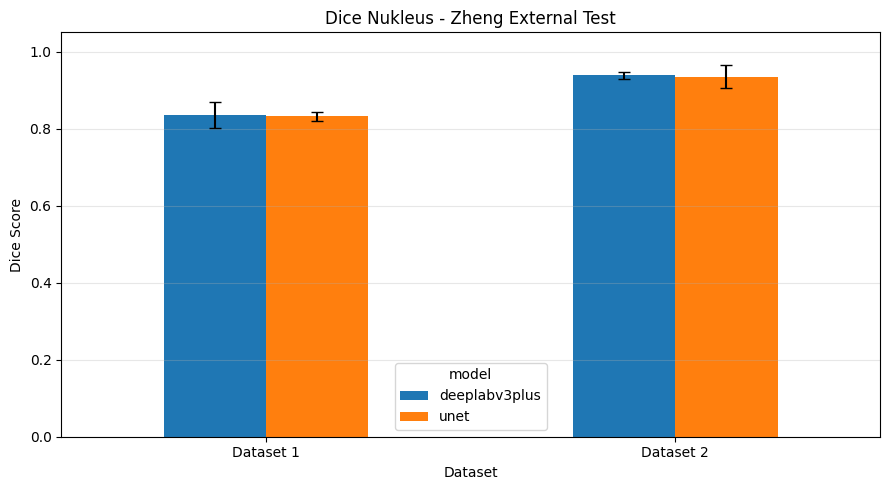

In [17]:
import matplotlib.pyplot as plt

plot_data = (
    per_seed.groupby(["dataset", "model"])[[
        "dice_cytoplasm", "dice_nucleus"
    ]]
    .agg(["mean", "std"])
)

for metric, title in [
    ("dice_cytoplasm", "Dice Sitoplasma"),
    ("dice_nucleus", "Dice Nukleus")
]:
    means = plot_data[(metric, "mean")].unstack("model")
    errors = plot_data[(metric, "std")].unstack("model")

    ax = means.plot(
        kind="bar",
        yerr=errors,
        capsize=4,
        figsize=(9, 5),
        rot=0
    )

    ax.set_title(title + " - Zheng External Test")
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Dice Score")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / f"{metric}_comparison.png",
        dpi=200
    )
    plt.show()

**Visualisasi prediksi vs ground truth**

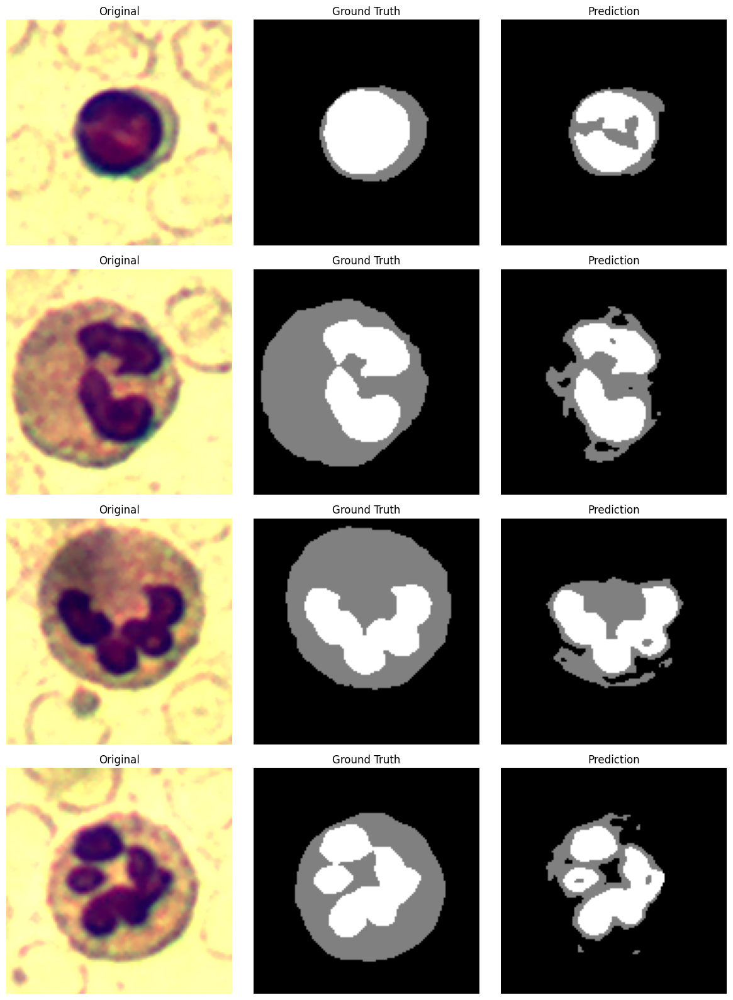

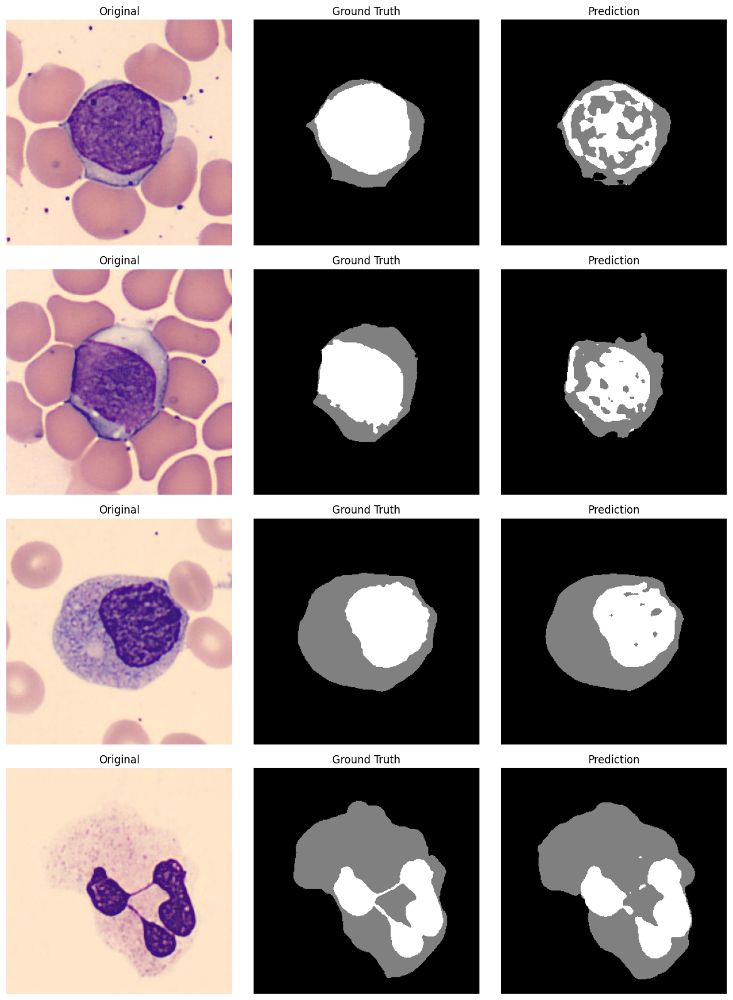

In [18]:
def visualize_prediction(model_name, seed, pairs, n=4):
    model = load_model(model_name, seed)

    selected = pairs[:n]
    fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))

    if n == 1:
        axes = axes[None, :]

    for idx, (image_path, mask_path) in enumerate(selected):
        original = Image.open(image_path).convert("RGB")
        gt = convert_mask(
            np.asarray(Image.open(mask_path).convert("L"))
        )

        tensor = image_transform(original)
        tensor = tensor.unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            logits = model(tensor)
            logits = F.interpolate(
                logits, size=gt.shape,
                mode="bilinear",
                align_corners=False
            )
            pred = logits.argmax(1)[0].cpu().numpy()

        axes[idx, 0].imshow(original)
        axes[idx, 0].set_title("Original")

        axes[idx, 1].imshow(
            gt, cmap="gray", vmin=0, vmax=2
        )
        axes[idx, 1].set_title("Ground Truth")

        axes[idx, 2].imshow(
            pred, cmap="gray", vmin=0, vmax=2
        )
        axes[idx, 2].set_title("Prediction")

        for ax in axes[idx]:
            ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / f"{model_name}_seed{seed}_predictions.png",
        dpi=200
    )
    plt.show()

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

visualize_prediction("unet", 42, pairs_d1)
visualize_prediction("deeplabv3plus", 42, pairs_d2)

**8 citra dengan segmentasi terburuk**

In [20]:
from pathlib import Path
import pandas as pd

ERROR_DIR = RESULT_DIR / "error_analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

# Menggunakan seed 42 sebagai contoh representatif.
# Seed ini ditetapkan sebelumnya, bukan dipilih
# berdasarkan performa eksternal.
SELECTED_SEED = 42

worst_results = []

for dataset_name in ["Dataset 1", "Dataset 2"]:
    for model_name in ["unet", "deeplabv3plus"]:

        subset = df_all[
            (df_all["dataset"] == dataset_name) &
            (df_all["model"] == model_name) &
            (df_all["seed"] == SELECTED_SEED)
        ].copy()

        worst = subset.sort_values(
            "dice_cytoplasm",
            ascending=True
        ).head(8)

        print("\n" + "=" * 60)
        print("DATASET:", dataset_name)
        print("MODEL:", model_name)
        print("=" * 60)

        display(worst[[
            "filename",
            "dice_cytoplasm",
            "dice_nucleus",
            "miou",
            "hd95_cytoplasm"
        ]])

        worst_results.append(worst)

        filename = (
            f"worst8_{model_name}_"
            f"{dataset_name.replace(' ', '_')}.csv"
        )

        worst.to_csv(
            ERROR_DIR / filename,
            index=False
        )

all_worst = pd.concat(
    worst_results,
    ignore_index=True
)

all_worst.to_csv(
    ERROR_DIR / "worst_cases_all.csv",
    index=False
)

print("\nAnalisis kasus terburuk tersimpan di:")
print(ERROR_DIR)


DATASET: Dataset 1
MODEL: unet


,filename,dice_cytoplasm,dice_nucleus,miou,hd95_cytoplasm
193,194.bmp,0.018772,0.279632,0.086009,30.010830
67,068.bmp,0.034690,0.653980,0.251757,23.028235
41,042.bmp,0.048955,0.557127,0.205608,20.518285
42,043.bmp,0.049106,0.575823,0.214745,19.239275
43,044.bmp,0.071382,0.589279,0.227363,24.166092
40,041.bmp,0.073284,0.513603,0.191785,27.037923
51,052.bmp,0.075748,0.542464,0.205772,25.992302
34,035.bmp,0.077748,0.285591,0.103515,33.958061



DATASET: Dataset 1
MODEL: deeplabv3plus


,filename,dice_cytoplasm,dice_nucleus,miou,hd95_cytoplasm
1267,068.bmp,0.001473,0.467317,0.152819,43.264843
1233,034.bmp,0.004632,0.164613,0.046005,35.349681
1393,194.bmp,0.005792,0.151767,0.042510,36.013886
1243,044.bmp,0.005888,0.582996,0.207191,42.867532
1234,035.bmp,0.006607,0.126880,0.035526,40.835579
1375,176.bmp,0.010204,0.541469,0.188186,31.900626
1394,195.bmp,0.023684,0.164948,0.050936,24.041631
1242,043.bmp,0.030585,0.342905,0.111231,43.600459



DATASET: Dataset 2
MODEL: unet


,filename,dice_cytoplasm,dice_nucleus,miou,hd95_cytoplasm
347,048.bmp,0.169455,0.519554,0.221757,38.032869
352,053.bmp,0.298767,0.540343,0.272901,36.769553
300,001.bmp,0.315234,0.526569,0.272242,40.711791
301,002.bmp,0.415690,0.621144,0.356428,31.123942
349,050.bmp,0.475591,0.501744,0.323435,39.560081
339,040.bmp,0.504807,0.920396,0.595075,112.342537
351,052.bmp,0.509282,0.671661,0.423637,31.870809
333,034.bmp,0.545082,0.879031,0.579409,27.924711



DATASET: Dataset 2
MODEL: deeplabv3plus


,filename,dice_cytoplasm,dice_nucleus,miou,hd95_cytoplasm
1547,048.bmp,0.315948,0.732238,0.382598,40.420255
1500,001.bmp,0.507597,0.731265,0.458246,34.637362
1552,053.bmp,0.549523,0.907404,0.604680,29.502401
1501,002.bmp,0.574529,0.790142,0.528066,27.000000
1517,018.bmp,0.595146,0.841821,0.575242,25.992302
1546,047.bmp,0.632575,0.571341,0.431259,35.634217
1516,017.bmp,0.637280,0.956146,0.691815,28.982235
1551,052.bmp,0.655758,0.849103,0.612801,27.586228



Analisis kasus terburuk tersimpan di:
/content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/error_analysis


**galeri visualisasi kasus terburuk**

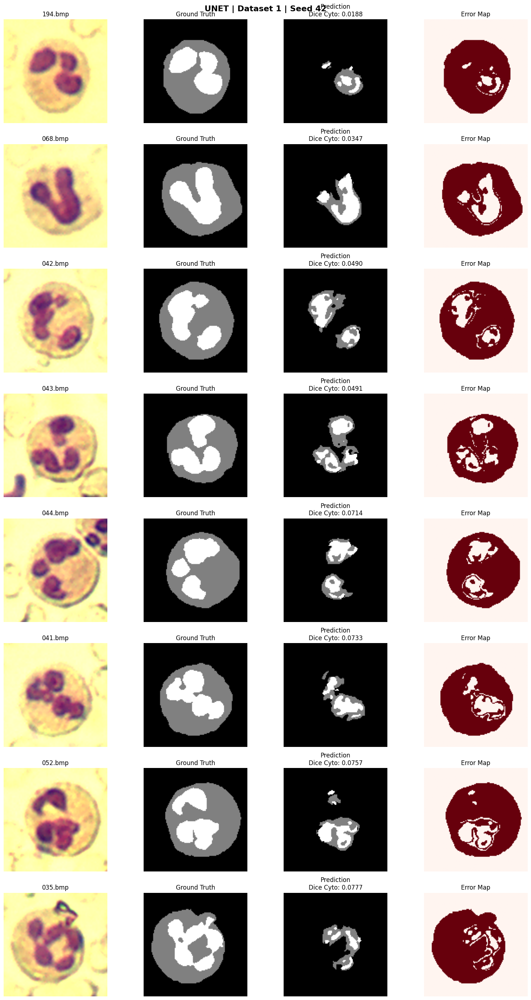

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/error_analysis/gallery/worst8_unet_Dataset_1.png


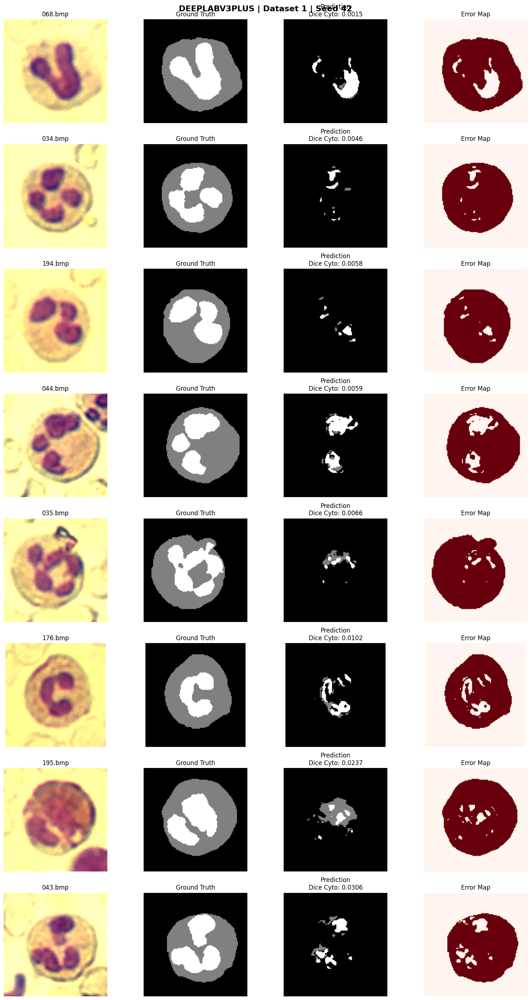

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/error_analysis/gallery/worst8_deeplabv3plus_Dataset_1.png


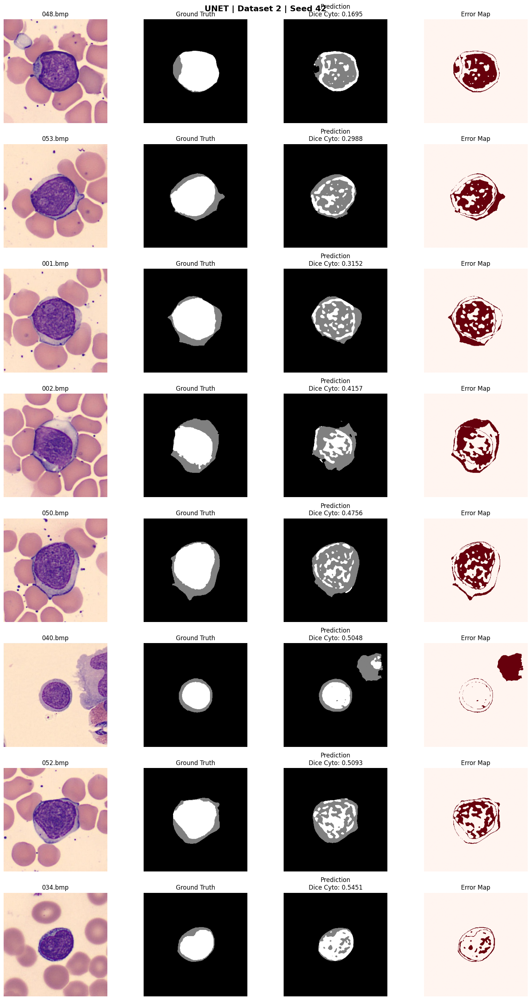

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/error_analysis/gallery/worst8_unet_Dataset_2.png


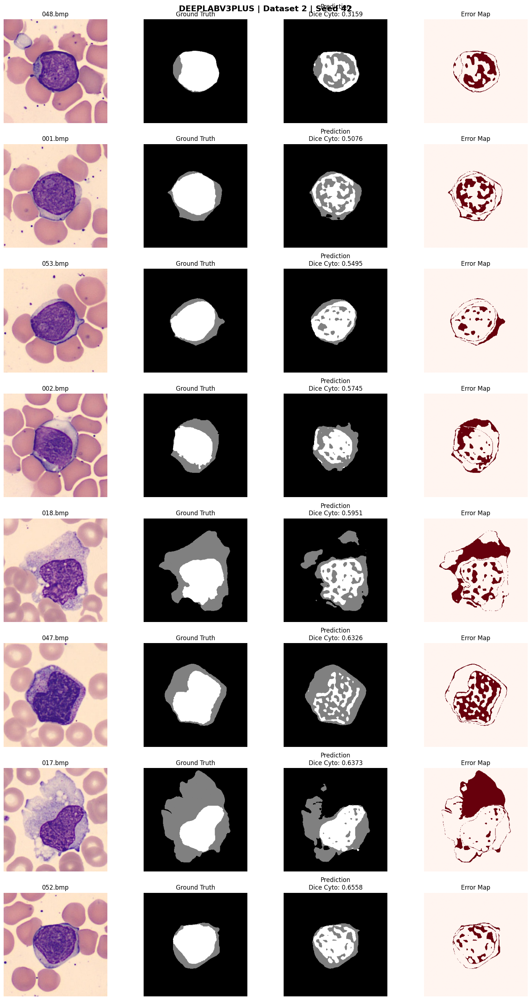

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/error_analysis/gallery/worst8_deeplabv3plus_Dataset_2.png


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
import gc

GALLERY_DIR = ERROR_DIR / "gallery"
GALLERY_DIR.mkdir(parents=True, exist_ok=True)

def visualize_worst_cases(
    model_name,
    dataset_name,
    seed=42,
    n=8
):
    model = load_model(model_name, seed)
    model.eval()

    if dataset_name == "Dataset 1":
        folder = dataset1
    else:
        folder = dataset2

    subset = df_all[
        (df_all["model"] == model_name) &
        (df_all["dataset"] == dataset_name) &
        (df_all["seed"] == seed)
    ]

    worst = subset.nsmallest(
        n, "dice_cytoplasm"
    )

    fig, axes = plt.subplots(
        n, 4,
        figsize=(16, n * 3.5),
        squeeze=False
    )

    for i, (_, row) in enumerate(worst.iterrows()):
        img_path = folder / row["filename"]
        mask_path = img_path.with_suffix(".png")

        original = Image.open(img_path).convert("RGB")
        gt = convert_mask(
            np.asarray(Image.open(mask_path).convert("L"))
        )

        x = image_transform(original)
        x = x.unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            logits = model(x)
            logits = F.interpolate(
                logits,
                size=gt.shape,
                mode="bilinear",
                align_corners=False
            )
            pred = logits.argmax(1)[0].cpu().numpy()

        error = (pred != gt).astype(np.uint8)

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(row["filename"])

        axes[i, 1].imshow(
            gt, cmap="gray", vmin=0, vmax=2
        )
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(
            pred, cmap="gray", vmin=0, vmax=2
        )
        axes[i, 2].set_title(
            f"Prediction\nDice Cyto: "
            f"{row['dice_cytoplasm']:.4f}"
        )

        axes[i, 3].imshow(error, cmap="Reds", vmin=0, vmax=1)
        axes[i, 3].set_title("Error Map")

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(
        f"{model_name.upper()} | {dataset_name} | Seed {seed}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    output = (
        GALLERY_DIR /
        f"worst8_{model_name}_"
        f"{dataset_name.replace(' ', '_')}.png"
    )

    plt.savefig(output, dpi=200, bbox_inches="tight")
    plt.show()

    print("Tersimpan:", output)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Jalankan untuk seluruh kombinasi
for dataset_name in ["Dataset 1", "Dataset 2"]:
    for model_name in ["unet", "deeplabv3plus"]:
        visualize_worst_cases(
            model_name,
            dataset_name,
            seed=42,
            n=8
        )

**hitung frekuensi kesalahan secara otomatis**

In [22]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import gc

def analyze_error_types(pred, gt):
    gt_cyto = gt == 1
    gt_nucleus = gt == 2
    gt_fg = gt > 0
    pred_fg = pred > 0

    # Persentase GT sitoplasma yang terlewat
    cyto_missed = (
        np.logical_and(gt_cyto, pred != 1).sum()
        / max(gt_cyto.sum(), 1)
    )

    # Persentase nukleus yang diprediksi sitoplasma
    nucleus_to_cyto = (
        np.logical_and(gt_nucleus, pred == 1).sum()
        / max(gt_nucleus.sum(), 1)
    )

    # Persentase prediksi foreground di luar GT sel
    extra_foreground = (
        np.logical_and(pred_fg, ~gt_fg).sum()
        / max(pred_fg.sum(), 1)
    )

    return {
        "cytoplasm_missed_rate": float(cyto_missed),
        "nucleus_to_cyto_rate": float(nucleus_to_cyto),
        "extra_foreground_rate": float(extra_foreground),

        # Ambang untuk analisis deskriptif,
        # bukan standar klinis
        "severe_cytoplasm_miss": int(cyto_missed > 0.5),
        "nucleus_cytoplasm_confusion": int(
            nucleus_to_cyto > 0.1
        ),
        "substantial_extra_foreground": int(
            extra_foreground > 0.1
        )
    }

error_rows = []

for dataset_name, pairs in [
    ("Dataset 1", pairs_d1),
    ("Dataset 2", pairs_d2)
]:
    for model_name in ["unet", "deeplabv3plus"]:

        model = load_model(model_name, 42)
        model.eval()

        for img_path, mask_path in pairs:
            original = Image.open(img_path).convert("RGB")
            gt = convert_mask(
                np.asarray(Image.open(mask_path).convert("L"))
            )

            x = image_transform(original)
            x = x.unsqueeze(0).to(DEVICE)

            with torch.inference_mode():
                logits = model(x)
                logits = F.interpolate(
                    logits,
                    size=gt.shape,
                    mode="bilinear",
                    align_corners=False
                )
                pred = logits.argmax(1)[0].cpu().numpy()

            errors = analyze_error_types(pred, gt)

            error_rows.append({
                "dataset": dataset_name,
                "model": model_name,
                "seed": 42,
                "filename": img_path.name,
                **errors
            })

        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

df_errors = pd.DataFrame(error_rows)

frequency_cols = [
    "severe_cytoplasm_miss",
    "nucleus_cytoplasm_confusion",
    "substantial_extra_foreground"
]

frequency = (
    df_errors.groupby(["dataset", "model"])[frequency_cols]
    .sum()
    .astype(int)
)

display(frequency)

frequency.to_csv(
    ERROR_DIR / "error_frequency_seed42.csv"
)

df_errors.to_csv(
    ERROR_DIR / "error_detail_seed42.csv",
    index=False
)

print("Analisis kesalahan selesai.")
print("Total citra-model yang dianalisis:", len(df_errors))

severe_cytoplasm_miss  nucleus_cytoplasm_confusion  \
dataset   model                                                               
Dataset 1 deeplabv3plus                    129                          261   
          unet                             106                          213   
Dataset 2 deeplabv3plus                      1                           29   
          unet                               4                           44   

                         substantial_extra_foreground  
dataset   model                                        
Dataset 1 deeplabv3plus                             5  
          unet                                      5  
Dataset 2 deeplabv3plus                             0  
          unet                                      1

Analisis kesalahan selesai.
Total citra-model yang dianalisis: 800


**Audit konfigurasi preprocessing**

In [23]:
# CELL 19 — AUDIT KONFIGURASI MODEL DAN PREPROCESSING

import torch
import segmentation_models_pytorch as smp
import pandas as pd

print("=" * 65)
print("AUDIT MODEL DAN PREPROCESSING")
print("=" * 65)

print("\n1. Informasi lingkungan")
print("PyTorch:", torch.__version__)
print("SMP:", smp.__version__)
print("Device:", DEVICE)
print("Input size evaluasi:", INPUT_SIZE)

print("\n2. Normalisasi input")
print("Transform:", image_transform)

print("\n3. Struktur output checkpoint")

for model_name in ["unet", "deeplabv3plus"]:
    path = checkpoint_files[
        f"{model_name}_final_seed42.pt"
    ]

    state = torch.load(
        str(path),
        map_location="cpu",
        weights_only=True
    )

    print(f"\nModel: {model_name}")
    print("Jumlah tensor:", len(state))

    model = build_model(model_name)

    model.load_state_dict(
        state,
        strict=True
    )

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    print("Jumlah parameter:", f"{total_params:,}")
    print("Parameter (juta):", round(total_params / 1e6, 3))

    print("Segmentation head:")
    for key in list(state.keys())[-5:]:
        print(" ", key, tuple(state[key].shape))

    del model, state

print("\n4. Pemetaan kelas evaluasi")
print("Background  : 0")
print("Sitoplasma : 1")
print("Nukleus    : 2")

print("\nAudit teknis selesai.")

AUDIT MODEL DAN PREPROCESSING

1. Informasi lingkungan
PyTorch: 2.14.1+cu130
SMP: 0.5.0
Device: cuda
Input size evaluasi: 256

2. Normalisasi input
Transform: Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

3. Struktur output checkpoint

Model: unet
Jumlah tensor: 278
Jumlah parameter: 24,436,659
Parameter (juta): 24.437
Segmentation head:
  decoder.blocks.4.conv2.1.running_mean (16,)
  decoder.blocks.4.conv2.1.running_var (16,)
  decoder.blocks.4.conv2.1.num_batches_tracked ()
  segmentation_head.0.weight (3, 16, 3, 3)
  segmentation_head.0.bias (3,)

Model: deeplabv3plus
Jumlah tensor: 277
Jumlah parameter: 22,437,971
Parameter (juta): 22.438
Segmentation head:
  decoder.block2.1.running_mean (256,)
  decoder.block2.1.running_var (256,)
  decoder.block2.1.num_batches_tracked ()
  segmentation_head.0.weight (3, 256, 1, 1)
  segmentation_head.0.bias (3,)

4

**memeriksa preprocessing pada notebook pelatihan asli**

In [24]:
# CELL 20 — AUDIT PREPROCESSING TRAINING ASLI

from pathlib import Path
import json

DRIVE_ROOT = Path("/content/drive/MyDrive")

KEYWORDS = [
    "Normalize(",
    "A.Normalize(",
    "Resize(",
    "A.Resize(",
    "IMG_SIZE",
    "IMAGE_SIZE",
    "INPUT_SIZE",
    "encoder_preprocessing",
    "get_preprocessing_fn",
    "mean=",
    "std=",
    "ToTensorV2",
    "ToTensor()"
]

# Cari notebook pelatihan
notebooks = [
    p for p in DRIVE_ROOT.rglob("*.ipynb")
    if "PROYEK UAS DEEP LEARNING" in str(p)
]

print("Jumlah notebook ditemukan:", len(notebooks))

for nb_path in notebooks:
    print("\n" + "=" * 75)
    print("NOTEBOOK:", nb_path.name)
    print("=" * 75)

    with open(nb_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    matches = 0

    for idx, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        found_lines = [
            (line_no, line)
            for line_no, line in enumerate(lines, start=1)
            if any(k.lower() in line.lower()
                   for k in KEYWORDS)
        ]

        if found_lines:
            matches += 1
            print(f"\nCell {idx + 1}:")

            for line_no, line in found_lines[:15]:
                print(f"  Baris {line_no}: {line.strip()}")

    if matches == 0:
        print("Tidak ditemukan konfigurasi preprocessing.")

print("\nAUDIT NOTEBOOK SELESAI")

Jumlah notebook ditemukan: 10

NOTEBOOK: 01_data_audit_raabin_wbc.ipynb

Cell 27:
  Baris 7: from albumentations.pytorch import ToTensorV2
  Baris 24: t = [A.Resize(size, size)]
  Baris 28: t += [A.Normalize(MEAN, STD), ToTensorV2()]

NOTEBOOK: 02_train_unet_deeplab.ipynb

Cell 14:
  Baris 2: run_experiment(OWNER, "resolution", "384", img_size=384)

NOTEBOOK: 03_eval_analysis.ipynb
Tidak ditemukan konfigurasi preprocessing.

NOTEBOOK: Salinan_dari_02_train_unet_deeplab_Aditya.ipynb

Cell 13:
  Baris 2: run_experiment(OWNER, "resolution", "384", img_size=384)

NOTEBOOK: Salinan_dari_03_eval_analysis_Aditya.ipynb
Tidak ditemukan konfigurasi preprocessing.

NOTEBOOK: Salinan_dari_02_train_unet_deeplab_iklil.ipynb

Cell 13:
  Baris 2: run_experiment(OWNER, "resolution", "384", img_size=384)

NOTEBOOK: Salinan_dari_03_eval_analysis_Iklil.ipynb
Tidak ditemukan konfigurasi preprocessing.

NOTEBOOK: Copy_of_02_train_unet_deeplab_Alpin.ipynb

Cell 14:
  Baris 2: run_experiment(OWNER, "resolutio

**pemeriksaan konfigurasi training asli**

In [25]:
# CELL 21 — CARI KONFIGURASI TRAINING FINAL

from pathlib import Path
import json

PROJECT_ROOT = DRIVE_ROOT / "PROYEK UAS DEEP LEARNING"

KEYWORDS = [
    "MEAN =", "STD =",
    "MEAN=", "STD=",
    "IMG_SIZE =", "IMAGE_SIZE =",
    "IMG_SIZE=", "IMAGE_SIZE=",
    "def run_experiment",
    "def make_transforms",
    "def build_transforms",
    "def get_transforms",
    "img_size=",
    "baseline",
    "final_seed",
    "final_model"
]

def inspect_source(text, filename):
    lines = text.splitlines()
    matches = []

    for i, line in enumerate(lines):
        if any(k.lower() in line.lower() for k in KEYWORDS):
            start = max(0, i - 2)
            end = min(len(lines), i + 5)

            snippet = "\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            )

            matches.append(snippet)

    if matches:
        print("\n" + "=" * 70)
        print("FILE:", filename)
        print("=" * 70)

        # Batasi output agar tidak terlalu panjang
        for match in matches[:20]:
            print(match)
            print("-" * 40)

# Periksa file Python
for path in PROJECT_ROOT.rglob("*.py"):
    try:
        source = path.read_text(encoding="utf-8")
        inspect_source(source, path.name)
    except Exception as e:
        print("Gagal membaca:", path, e)

# Periksa notebook utama
for name in [
    "01_data_audit_raabin_wbc.ipynb",
    "02_train_unet_deeplab.ipynb"
]:
    found = list(PROJECT_ROOT.rglob(name))

    if not found:
        print("Notebook tidak ditemukan:", name)
        continue

    with open(found[0], encoding="utf-8") as f:
        notebook = json.load(f)

    for index, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell.get("source", []))
        inspect_source(
            source,
            f"{name} | Cell {index+1}"
        )

print("\nPemeriksaan selesai.")


FILE: data.py
8: DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
9: BMP = "/content/raabin_gt/bmp"
10: MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # normalisasi ImageNet
11: 
12: def load_split(scheme, part):
13:     # scheme: grouped | random | cross_session ; part: train | val | test
14:     return pd.read_csv(f"{DRIVE}/splits/{scheme}_{part}.csv")
----------------------------------------

FILE: train.py
3: 
4: Satu panggilan run_experiment(...) = satu run = satu baris di logs/log_<owner>.csv.
5: Faktor ablasi diubah lewat argumen fungsi; sisanya tetap pada baseline:
6:     U-Net ResNet-34 (ImageNet), loss CE+Dice, split 'grouped',
7:     augmentasi warna aktif, resolusi 256, 20 epoch, seed 42.
8: 
9: Aturan penting (Kisi-Kisi 3.2):
----------------------------------------
83: 
84: # ---------------------------------------------------------------------- 1 run
85: def run_experiment(owner, ablation, factor_value,
86:                    arch="unet", encoder="r

**verifikaksi kode preprocesing dan metrik asli**

In [26]:
# CELL 22 — VERIFIKASI DATA.PY DAN METRICS.PY

from pathlib import Path
import inspect

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
)

for filename in ["data.py", "metrics.py"]:
    files = list(PROJECT_ROOT.rglob(filename))

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    if not files:
        print("File tidak ditemukan")
        continue

    # Utamakan file pada folder code
    files.sort(key=lambda p: (
        "code" not in p.parts,
        len(p.parts)
    ))

    selected = files[0]
    print("Path:", selected)

    source = selected.read_text(encoding="utf-8")

    # Tampilkan dengan nomor baris
    for i, line in enumerate(source.splitlines(), start=1):
        print(f"{i:03d}: {line}")


FILE: data.py
Path: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/code/data.py
001: 
002: import os, numpy as np, pandas as pd, torch
003: from PIL import Image
004: from torch.utils.data import Dataset
005: import albumentations as A
006: from albumentations.pytorch import ToTensorV2
007: 
008: DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
009: BMP = "/content/raabin_gt/bmp"
010: MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # normalisasi ImageNet
011: 
012: def load_split(scheme, part):
013:     # scheme: grouped | random | cross_session ; part: train | val | test
014:     return pd.read_csv(f"{DRIVE}/splits/{scheme}_{part}.csv")
015: 
016: def _path(name, mask):
017:     for s in ("Train", "Test"):
018:         p = f"{BMP}/{s}_GT_bmp/{name}" if mask else f"{BMP}/{s}_bmp/{name}"
019:         if os.path.exists(p): return p
020:     raise FileNotFoundError(name)
021: 
022: def make_tf(train, size=256, color_aug=True):
023:     t = [A.Resize(size, size)]
024:

**evaluasi ulang menggunakan metrics.py asli**

In [27]:
# CELL 24 — FINAL EXTERNAL EVALUATION
# Menggunakan metrics.py asli proyek Raabin-WBC

import sys
import gc
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
)

CODE_DIR = PROJECT_ROOT / "code"
sys.path.insert(0, str(CODE_DIR))

import metrics as original_metrics

FINAL_DIR = RESULT_DIR / "final_verified"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

device_obj = torch.device(DEVICE)

datasets = {
    "Dataset 1": loader_d1,
    "Dataset 2": loader_d2
}

def evaluate_verified(model, loader, dataset_name,
                      model_name, seed):
    records = []

    model.eval()

    for batch in tqdm(
        loader,
        desc=f"{model_name} seed{seed} - {dataset_name}"
    ):
        x = batch["image"]
        gt = batch["mask"][0].numpy()
        filename = batch["filename"][0]

        # Menggunakan fungsi prediksi asli
        pred = original_metrics.predict_labels(
            model=model,
            x=x,
            out_hw=gt.shape,
            device=device_obj,
            amp=True
        )[0]

        # Menggunakan seluruh metrik asli
        result = original_metrics.per_image_metrics(
            pred,
            gt,
            with_hd95=True
        )

        records.append({
            "dataset": dataset_name,
            "model": model_name,
            "seed": seed,
            "filename": filename,
            **result
        })

    return pd.DataFrame(records)

verified_results = []

for model_name in ["unet", "deeplabv3plus"]:
    for seed in [42, 43, 44]:

        print(
            f"\nMODEL: {model_name.upper()} "
            f"| SEED: {seed}"
        )

        model = load_model(model_name, seed)

        for dataset_name, loader in datasets.items():
            df = evaluate_verified(
                model,
                loader,
                dataset_name,
                model_name,
                seed
            )

            verified_results.append(df)

            filename = (
                f"{model_name}_seed{seed}_"
                f"{dataset_name.replace(' ', '_')}.csv"
            )

            df.to_csv(
                FINAL_DIR / filename,
                index=False
            )

            print("Tersimpan:", filename)

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

df_verified = pd.concat(
    verified_results,
    ignore_index=True
)

df_verified.to_csv(
    FINAL_DIR / "external_verified_all.csv",
    index=False
)

assert len(df_verified) == 2400

print("\nEVALUASI TERVERIFIKASI SELESAI")
print("Jumlah baris:", len(df_verified))
print("Folder:", FINAL_DIR)


MODEL: UNET | SEED: 42


unet seed42 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

Tersimpan: unet_seed42_Dataset_1.csv


unet seed42 - Dataset 2:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: unet_seed42_Dataset_2.csv

MODEL: UNET | SEED: 43


unet seed43 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

... (15 outputs left out)

deeplabv3plus seed44 - Dataset 1:   0%|          | 0/300 [00:00<?, ?it/s]

Tersimpan: deeplabv3plus_seed44_Dataset_1.csv


deeplabv3plus seed44 - Dataset 2:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: deeplabv3plus_seed44_Dataset_2.csv

EVALUASI TERVERIFIKASI SELESAI
Jumlah baris: 2400
Folder: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified


**tabel hasil akhir**

In [28]:
# CELL 25 — FINAL SUMMARY

METRICS_FINAL = [
    "dice_cyto",
    "dice_nuc",
    "iou_bg",
    "iou_cyto",
    "iou_nuc",
    "miou",
    "hd95_cyto",
    "hd95_nuc"
]

# Rata-rata per seed
per_seed_verified = (
    df_verified
    .groupby(["dataset", "model", "seed"])[METRICS_FINAL]
    .mean()
    .reset_index()
)

per_seed_verified.to_csv(
    FINAL_DIR / "external_verified_per_seed.csv",
    index=False
)

# Statistik antar-seed
summary_verified = (
    per_seed_verified
    .groupby(["dataset", "model"])[METRICS_FINAL]
    .agg(["mean", "std"])
)

formatted = pd.DataFrame(
    index=summary_verified.index
)

for metric in METRICS_FINAL:
    means = summary_verified[(metric, "mean")]
    stds = summary_verified[(metric, "std")]

    formatted[metric] = [
        f"{m:.4f} ± {s:.4f}"
        for m, s in zip(means, stds)
    ]

print("HASIL FINAL UJI EKSTERNAL")
display(formatted)

formatted.to_csv(
    FINAL_DIR / "external_verified_summary.csv"
)

# Pemeriksaan perubahan Dice terhadap evaluasi lama
old = df_all.rename(columns={
    "dice_cytoplasm": "old_dice_cyto",
    "dice_nucleus": "old_dice_nuc"
})

merged = df_verified.merge(
    old[[
        "dataset", "model", "seed", "filename",
        "old_dice_cyto", "old_dice_nuc"
    ]],
    on=["dataset", "model", "seed", "filename"],
    validate="one_to_one"
)

print("\nPERBEDAAN MAKSIMUM DICE DARI EVALUASI LAMA")

print(
    "Sitoplasma:",
    (merged["dice_cyto"] -
     merged["old_dice_cyto"]).abs().max()
)

print(
    "Nukleus:",
    (merged["dice_nuc"] -
     merged["old_dice_nuc"]).abs().max()
)

print("\nRingkasan disimpan di:", FINAL_DIR)

HASIL FINAL UJI EKSTERNAL


dice_cyto         dice_nuc           iou_bg  \
dataset   model                                                              
Dataset 1 deeplabv3plus  0.6388 ± 0.0975  0.8360 ± 0.0343  0.8920 ± 0.0261   
          unet           0.6542 ± 0.0302  0.8324 ± 0.0120  0.8969 ± 0.0076   
Dataset 2 deeplabv3plus  0.8841 ± 0.0099  0.9381 ± 0.0098  0.9830 ± 0.0010   
          unet           0.8732 ± 0.0230  0.9346 ± 0.0300  0.9815 ± 0.0008   

                                iou_cyto          iou_nuc             miou  \
dataset   model                                                              
Dataset 1 deeplabv3plus  0.5177 ± 0.0936  0.7499 ± 0.0484  0.7199 ± 0.0443   
          unet           0.5378 ± 0.0312  0.7477 ± 0.0102  0.7275 ± 0.0101   
Dataset 2 deeplabv3plus  0.8067 ± 0.0117  0.8900 ± 0.0150  0.8933 ± 0.0091   
          unet           0.7951 ± 0.0292  0.8869 ± 0.0445  0.8878 ± 0.0247   

                                hd95_cyto          hd95_nuc  
dataset   model                                              
Dataset 1 deeplabv3plus  10.4269 ± 2.0060   7.4660 ± 0.6543  
          unet            9.6045 ± 0.8676   7.6972 ± 0.1298  
Dataset 2 deeplabv3plus  12.6867 ± 1.4989  16.8053 ± 1.5245  
          unet           14.4395 ± 2.6649  17.0664 ± 2.1593


PERBEDAAN MAKSIMUM DICE DARI EVALUASI LAMA
Sitoplasma: 0.003281515686321901
Nukleus: 0.004756020480393253

Ringkasan disimpan di: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified


**ukur latensi GPU**

In [29]:
# CELL 26 — PENGUKURAN EFISIENSI GPU

import time
import gc
import numpy as np
import pandas as pd
import torch

assert torch.cuda.is_available(), "Aktifkan GPU di Colab"

WARMUP = 20
REPEAT = 100

gpu_name = torch.cuda.get_device_name(0)
latency_results = []

for model_name in ["unet", "deeplabv3plus"]:
    for seed in [42, 43, 44]:

        model = load_model(model_name, seed)
        model.eval()

        # Input batch 1, resolusi 256x256
        x = torch.randn(
            1, 3, INPUT_SIZE, INPUT_SIZE,
            device=DEVICE
        )

        with torch.inference_mode():
            for _ in range(WARMUP):
                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    _ = model(x)

        torch.cuda.synchronize()
        times = []

        with torch.inference_mode():
            for _ in range(REPEAT):
                torch.cuda.synchronize()
                start = time.perf_counter()

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):
                    _ = model(x)

                torch.cuda.synchronize()
                times.append(
                    (time.perf_counter() - start) * 1000
                )

        latency_results.append({
            "model": model_name,
            "seed": seed,
            "parameters_million": sum(
                p.numel() for p in model.parameters()
            ) / 1e6,
            "latency_mean_ms": np.mean(times),
            "latency_std_ms": np.std(times, ddof=1),
            "latency_p95_ms": np.percentile(times, 95),
            "gpu": gpu_name,
            "input_size": INPUT_SIZE,
            "precision": "FP16",
            "batch_size": 1
        })

        print(
            f"{model_name} seed {seed}: "
            f"{np.mean(times):.3f} ms"
        )

        del model, x
        gc.collect()
        torch.cuda.empty_cache()

df_latency = pd.DataFrame(latency_results)

display(df_latency.round(3))

df_latency.to_csv(
    FINAL_DIR / "gpu_latency_final.csv",
    index=False
)

summary_latency = (
    df_latency.groupby("model")
    .agg(
        parameters_million=("parameters_million", "mean"),
        latency_ms=("latency_mean_ms", "mean"),
        latency_sd=("latency_mean_ms", "std")
    )
)

print("\n=== RINGKASAN EFISIENSI ===")
display(summary_latency.round(3))

summary_latency.to_csv(
    FINAL_DIR / "gpu_latency_summary.csv"
)

print("\nGPU:", gpu_name)

unet seed 42: 11.925 ms
unet seed 43: 8.077 ms
unet seed 44: 7.853 ms
deeplabv3plus seed 42: 7.787 ms
deeplabv3plus seed 43: 7.532 ms
deeplabv3plus seed 44: 7.348 ms


,model,seed,parameters_million,latency_mean_ms,latency_std_ms,latency_p95_ms,gpu,input_size,precision,batch_size
0,unet,42,24.437,11.925,2.643,15.564,Tesla T4,256,FP16,1
1,unet,43,24.437,8.077,1.301,11.613,Tesla T4,256,FP16,1
2,unet,44,24.437,7.853,1.008,8.417,Tesla T4,256,FP16,1
3,deeplabv3plus,42,22.438,7.787,1.087,9.232,Tesla T4,256,FP16,1
4,deeplabv3plus,43,22.438,7.532,0.975,9.623,Tesla T4,256,FP16,1
5,deeplabv3plus,44,22.438,7.348,0.925,8.336,Tesla T4,256,FP16,1



=== RINGKASAN EFISIENSI ===


,parameters_million,latency_ms,latency_sd
model,,,
deeplabv3plus,22.438,7.556,0.220
unet,24.437,9.285,2.289



GPU: Tesla T4


In [30]:
# CELL 27 — AUDIT DUPLIKASI RAABIN VS ZHENG

!pip -q install ImageHash

import hashlib
import imagehash
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

RAABIN_ROOT = Path("/content/raabin_gt/bmp")
AUDIT_DIR = FINAL_DIR / "leakage_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

assert RAABIN_ROOT.exists(), (
    "Folder Raabin belum tersedia di /content/raabin_gt/bmp. "
    "Mount atau ekstrak dataset Raabin terlebih dahulu."
)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def calculate_hashes(path):
    with Image.open(path) as im:
        phash = imagehash.phash(im.convert("RGB"))

    return {
        "sha256": sha256_file(path),
        "phash": phash
    }

# Ambil citra Raabin saja, bukan mask GT
raabin_files = sorted([
    p for p in RAABIN_ROOT.rglob("*.bmp")
    if "_GT_bmp" not in str(p)
    and p.parent.name in {"Train_bmp", "Test_bmp"}
])

zheng_files = (
    [p[0] for p in pairs_d1] +
    [p[0] for p in pairs_d2]
)

print("Raabin images:", len(raabin_files))
print("Zheng images:", len(zheng_files))

assert len(raabin_files) > 0, (
    "Tidak ditemukan citra sumber Raabin."
)
assert len(zheng_files) == 400

raabin_hashes = []
zheng_hashes = []

for path in tqdm(raabin_files, desc="Hash Raabin"):
    hashes = calculate_hashes(path)
    raabin_hashes.append({
        "path": str(path),
        **hashes
    })

for path in tqdm(zheng_files, desc="Hash Zheng"):
    hashes = calculate_hashes(path)
    zheng_hashes.append({
        "path": str(path),
        **hashes
    })

# Audit SHA-256: duplikasi byte-identik
raabin_sha = {}
for item in raabin_hashes:
    raabin_sha.setdefault(item["sha256"], []).append(item["path"])

exact_matches = []

for item in zheng_hashes:
    for rpath in raabin_sha.get(item["sha256"], []):
        exact_matches.append({
            "raabin": rpath,
            "zheng": item["path"],
            "match_type": "exact_sha256"
        })

# Audit pHash dengan jarak Hamming <= 5
# Ambang ini adalah kandidat kemiripan untuk inspeksi manual.
PHASH_THRESHOLD = 5
near_matches = []

for z in tqdm(zheng_hashes, desc="Compare pHash"):
    for r in raabin_hashes:
        distance = z["phash"] - r["phash"]

        if distance <= PHASH_THRESHOLD:
            near_matches.append({
                "raabin": r["path"],
                "zheng": z["path"],
                "phash_distance": int(distance)
            })

df_exact = pd.DataFrame(
    exact_matches,
    columns=["raabin", "zheng", "match_type"]
)

df_near = pd.DataFrame(
    near_matches,
    columns=["raabin", "zheng", "phash_distance"]
)

df_exact.to_csv(
    AUDIT_DIR / "exact_duplicates.csv",
    index=False
)

df_near.to_csv(
    AUDIT_DIR / "phash_candidates.csv",
    index=False
)

print("\n=== HASIL AUDIT DUPLIKASI ===")
print("Exact duplicates:", len(df_exact))
print("Kandidat mirip (pHash <= 5):", len(df_near))

if len(df_near) > 0:
    display(df_near.head(20))

print("\nTersimpan:", AUDIT_DIR)

AssertionError: Folder Raabin belum tersedia di /content/raabin_gt/bmp. Mount atau ekstrak dataset Raabin terlebih dahulu.

In [31]:
# CELL 27A — CARI DATASET RAABIN

from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

print("=" * 65)
print("MENCARI DATASET RAABIN-WBC")
print("=" * 65)

keywords = [
    "raabin",
    "train_bmp",
    "test_bmp",
    "gt_bmp"
]

found = []

for p in DRIVE_ROOT.rglob("*"):
    name = p.name.lower()

    if any(k in name for k in keywords):
        found.append(p)

print("Jumlah hasil ditemukan:", len(found))

for p in found[:60]:
    jenis = "FOLDER" if p.is_dir() else "FILE"
    print(f"[{jenis}] {p}")

if not found:
    print(
        "\nDataset Raabin belum ditemukan di My Drive. "
        "Periksa folder Dibagikan kepada saya atau lokasi ZIP aslinya."
    )

MENCARI DATASET RAABIN-WBC
Jumlah hasil ditemukan: 2
[FILE] /content/drive/MyDrive/Colab Notebooks/01_data_audit_raabin_wbc.ipynb
[FILE] /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/Notebooks/01_data_audit_raabin_wbc.ipynb


In [32]:
# CELL 27B — PERIKSA ARSIP ZIP

from pathlib import Path
import zipfile

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
)

zip_files = list(PROJECT_ROOT.rglob("*.zip"))

print("Jumlah ZIP dalam proyek:", len(zip_files))

for path in zip_files:
    print("\nZIP:", path.name)

    try:
        with zipfile.ZipFile(path) as z:
            names = z.namelist()
            print("Jumlah isi:", len(names))

            for name in names[:8]:
                print(" ", name)

    except Exception as e:
        print("Tidak dapat dibaca:", e)

Jumlah ZIP dalam proyek: 0


In [33]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
)

rar_files = list(PROJECT_ROOT.rglob("*.rar"))

print("Jumlah arsip RAR:", len(rar_files))

for p in rar_files:
    print(p.name, "|", round(p.stat().st_size / 1e6, 2), "MB")
    print("Path:", p)

Jumlah arsip RAR: 2
GrTh.rar | 52.99 MB
Path: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/GrTh.rar
GroundTruths_bmpformat.rar | 294.73 MB
Path: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/GroundTruths_bmpformat.rar


In [34]:
# Install alat ekstraksi RAR
!apt-get -qq update
!apt-get -qq install -y unrar || apt-get -qq install -y p7zip-full

import subprocess
from pathlib import Path

EXTRACT_ROOT = Path("/content/raabin_gt")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

for rar_path in rar_files:
    print("\nMengekstrak:", rar_path.name)

    result = subprocess.run(
        [
            "7z", "x",
            str(rar_path),
            f"-o{EXTRACT_ROOT}",
            "-y"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print("Gagal:", result.stderr[-1500:])
    else:
        print("Berhasil:", rar_path.name)

print("\n=== STRUKTUR FOLDER ===")

for p in EXTRACT_ROOT.rglob("*"):
    if p.is_dir():
        print(p.relative_to(EXTRACT_ROOT))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

Mengekstrak: GrTh.rar
Gagal: .jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-1-3_15_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-2_61_2.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-3_147_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-3_51_3.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-3_66_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-3_8_2.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-4_156_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-4_176_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-4_6_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-3-5_26_1.jpg
ERROR: Unsupported Method : GrTh/Original/Neutrophil/95-9-4-3_44_

In [35]:
# INSTAL DAN PERIKSA UNRAR

import shutil
import subprocess

print("Memeriksa program ekstraksi RAR...")

subprocess.run(
    "apt-get update -qq && apt-get install -y unrar",
    shell=True,
    check=False
)

print("\nLokasi unrar:", shutil.which("unrar"))
print("Lokasi unar:", shutil.which("unar"))
print("Lokasi 7z:", shutil.which("7z"))

if shutil.which("unrar"):
    subprocess.run(["unrar"], capture_output=False)

Memeriksa program ekstraksi RAR...

Lokasi unrar: /usr/bin/unrar
Lokasi unar: None
Lokasi 7z: /usr/bin/7z


In [36]:
# EKSTRAK DATASET RAABIN DENGAN UNRAR

from pathlib import Path
import subprocess

EXTRACT_ROOT = Path("/content/raabin_gt")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

for rar_path in rar_files:
    print("\n" + "=" * 60)
    print("Mengekstrak:", rar_path.name)
    print("=" * 60)

    result = subprocess.run(
        [
            "unrar",
            "x",
            "-o+",
            str(rar_path),
            str(EXTRACT_ROOT) + "/"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print("BERHASIL:", rar_path.name)
    else:
        print("GAGAL:", rar_path.name)
        print(result.stderr[-1500:])
        print(result.stdout[-1500:])

print("\nProses ekstraksi selesai.")


Mengekstrak: GrTh.rar
BERHASIL: GrTh.rar

Mengekstrak: GroundTruths_bmpformat.rar
BERHASIL: GroundTruths_bmpformat.rar

Proses ekstraksi selesai.


In [38]:
# CEK HASIL EKSTRAKSI

from pathlib import Path

ROOT = Path("/content/raabin_gt")

folders = [
    "Train_bmp",
    "Test_bmp",
    "Train_GT_bmp",
    "Test_GT_bmp"
]

print("=== VERIFIKASI DATASET RAABIN ===")

for folder in folders:
    path = ROOT / folder

    if path.exists():
        files = list(path.rglob("*.bmp"))
        print(f"{folder}: {len(files)} file BMP")
    else:
        print(f"{folder}: TIDAK DITEMUKAN")

print("\nVerifikasi selesai.")

=== VERIFIKASI DATASET RAABIN ===
Train_bmp: 912 file BMP
Test_bmp: 233 file BMP
Train_GT_bmp: 912 file BMP
Test_GT_bmp: 233 file BMP

Verifikasi selesai.


**audit duplikasi Rabbin-Zheng**

In [39]:
# CELL 28 — AUDIT DUPLIKASI RAABIN VS ZHENG

!pip -q install ImageHash

import hashlib
import imagehash
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

RAABIN_ROOT = Path("/content/raabin_gt")
AUDIT_DIR = FINAL_DIR / "leakage_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# Ambil hanya citra asli Raabin, bukan mask GT
raabin_files = sorted(
    list((RAABIN_ROOT / "Train_bmp").glob("*.bmp")) +
    list((RAABIN_ROOT / "Test_bmp").glob("*.bmp"))
)

# Ambil citra asli Zheng, bukan PNG ground truth
zheng_files = [
    img_path for img_path, mask_path
    in (pairs_d1 + pairs_d2)
]

print("Jumlah citra Raabin:", len(raabin_files))
print("Jumlah citra Zheng:", len(zheng_files))

assert len(raabin_files) == 1145
assert len(zheng_files) == 400

def sha256_file(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(block)

    return sha.hexdigest()

def hash_image(path):
    with Image.open(path) as im:
        ph = imagehash.phash(im.convert("RGB"))

    return {
        "sha256": sha256_file(path),
        "phash": ph
    }

raabin_hashes = []
zheng_hashes = []

for path in tqdm(raabin_files, desc="Hash Raabin"):
    hashes = hash_image(path)
    raabin_hashes.append({
        "path": str(path),
        **hashes
    })

for path in tqdm(zheng_files, desc="Hash Zheng"):
    hashes = hash_image(path)
    zheng_hashes.append({
        "path": str(path),
        **hashes
    })

# 1. Duplikasi byte-identik (SHA-256)
raabin_sha = {}

for item in raabin_hashes:
    raabin_sha.setdefault(
        item["sha256"], []
    ).append(item["path"])

exact_matches = []

for item in zheng_hashes:
    for matched_path in raabin_sha.get(
        item["sha256"], []
    ):
        exact_matches.append({
            "raabin": matched_path,
            "zheng": item["path"]
        })

# 2. Kandidat citra sangat mirip (pHash)
PHASH_THRESHOLD = 5
near_matches = []

for z in tqdm(zheng_hashes, desc="Compare pHash"):
    for r in raabin_hashes:
        distance = z["phash"] - r["phash"]

        if distance <= PHASH_THRESHOLD:
            near_matches.append({
                "raabin": r["path"],
                "zheng": z["path"],
                "phash_distance": int(distance)
            })

df_exact = pd.DataFrame(
    exact_matches,
    columns=["raabin", "zheng"]
)

df_near = pd.DataFrame(
    near_matches,
    columns=["raabin", "zheng", "phash_distance"]
)

df_exact.to_csv(
    AUDIT_DIR / "exact_duplicates.csv",
    index=False
)

df_near.to_csv(
    AUDIT_DIR / "phash_candidates.csv",
    index=False
)

print("\n=== HASIL AUDIT DUPLIKASI ===")
print("Duplikasi identik SHA-256:", len(df_exact))
print("Kandidat mirip pHash <= 5:", len(df_near))

if not df_near.empty:
    display(df_near.head(20))

print("\nHasil disimpan di:", AUDIT_DIR)

Jumlah citra Raabin: 1145
Jumlah citra Zheng: 400


Hash Raabin:   0%|          | 0/1145 [00:00<?, ?it/s]

Hash Zheng:   0%|          | 0/400 [00:00<?, ?it/s]

Compare pHash:   0%|          | 0/400 [00:00<?, ?it/s]


=== HASIL AUDIT DUPLIKASI ===
Duplikasi identik SHA-256: 0
Kandidat mirip pHash <= 5: 0

Hasil disimpan di: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/leakage_audit


**perbarui daftar 8 citra terburuk**

In [40]:
# CELL 29 — DAFTAR 8 KASUS TERBURUK FINAL FP16

from pathlib import Path
import pandas as pd

# Gunakan hasil evaluasi final
if "df_verified" not in globals():
    df_verified = pd.read_csv(
        FINAL_DIR / "external_verified_all.csv"
    )

ERROR_FINAL_DIR = FINAL_DIR / "error_analysis_fp16"
ERROR_FINAL_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_SEED = 42
worst_final_results = []

for dataset_name in ["Dataset 1", "Dataset 2"]:
    for model_name in ["unet", "deeplabv3plus"]:

        subset = df_verified[
            (df_verified["dataset"] == dataset_name) &
            (df_verified["model"] == model_name) &
            (df_verified["seed"] == SELECTED_SEED)
        ].copy()

        assert len(subset) == (
            300 if dataset_name == "Dataset 1" else 100
        )

        worst = subset.nsmallest(
            8, "dice_cyto"
        ).copy()

        print("\n" + "=" * 60)
        print("MODEL:", model_name)
        print("DATASET:", dataset_name)
        print("=" * 60)

        display(worst[[
            "filename",
            "dice_cyto",
            "dice_nuc",
            "miou",
            "hd95_cyto"
        ]])

        worst_final_results.append(worst)

        output = (
            ERROR_FINAL_DIR /
            f"worst8_{model_name}_"
            f"{dataset_name.replace(' ', '_')}.csv"
        )

        worst.to_csv(output, index=False)

df_worst_final = pd.concat(
    worst_final_results,
    ignore_index=True
)

df_worst_final.to_csv(
    ERROR_FINAL_DIR / "worst_cases_all_fp16.csv",
    index=False
)

print("\nDaftar 8 kasus terburuk FP16 berhasil disimpan.")
print("Jumlah baris:", len(df_worst_final))
print("Folder:", ERROR_FINAL_DIR)


MODEL: unet
DATASET: Dataset 1


,filename,dice_cyto,dice_nuc,miou,hd95_cyto
193,194.bmp,0.018767,0.279632,0.283406,29.732137
67,068.bmp,0.034697,0.655260,0.384550,23.028235
41,042.bmp,0.048955,0.557127,0.357791,20.518285
42,043.bmp,0.049571,0.576332,0.388729,19.235384
43,044.bmp,0.071382,0.589279,0.374593,24.166092
40,041.bmp,0.073284,0.514215,0.357001,27.037923
51,052.bmp,0.075748,0.543578,0.355291,25.992302
34,035.bmp,0.077765,0.286328,0.287615,33.958061



MODEL: deeplabv3plus
DATASET: Dataset 1


,filename,dice_cyto,dice_nuc,miou,hd95_cyto
1267,068.bmp,0.001473,0.468423,0.302938,43.264843
1233,034.bmp,0.004632,0.165517,0.244955,35.349681
1393,194.bmp,0.005792,0.151767,0.244339,36.013886
1243,044.bmp,0.005887,0.582996,0.351981,42.837706
1234,035.bmp,0.006604,0.126880,0.230656,40.845968
1375,176.bmp,0.010204,0.542333,0.348893,31.900626
1394,195.bmp,0.023694,0.164948,0.244446,24.041631
1242,043.bmp,0.030585,0.342905,0.297188,43.600459



MODEL: unet
DATASET: Dataset 2


,filename,dice_cyto,dice_nuc,miou,hd95_cyto
347,048.bmp,0.169223,0.519355,0.476733,38.036154
352,053.bmp,0.298750,0.540836,0.507043,36.769553
300,001.bmp,0.315303,0.526848,0.506491,40.752892
301,002.bmp,0.415478,0.621144,0.555816,31.123942
349,050.bmp,0.475645,0.501927,0.543622,39.554385
339,040.bmp,0.504803,0.920497,0.710984,112.349435
351,052.bmp,0.509451,0.672001,0.612434,31.866887
333,034.bmp,0.545455,0.879318,0.717500,27.903200



MODEL: deeplabv3plus
DATASET: Dataset 2


,filename,dice_cyto,dice_nuc,miou,hd95_cyto
1547,048.bmp,0.315775,0.731948,0.585982,40.420255
1500,001.bmp,0.507430,0.731265,0.634406,34.536936
1552,053.bmp,0.549305,0.907239,0.729200,29.502401
1501,002.bmp,0.574898,0.790067,0.674216,27.000000
1517,018.bmp,0.595318,0.841660,0.673103,25.961510
1546,047.bmp,0.632401,0.570713,0.616997,35.774866
1516,017.bmp,0.636986,0.956040,0.732865,28.554751
1551,052.bmp,0.655694,0.848911,0.738930,27.586228



Daftar 8 kasus terburuk FP16 berhasil disimpan.
Jumlah baris: 32
Folder: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16


**galeri kesalahan final FP16**

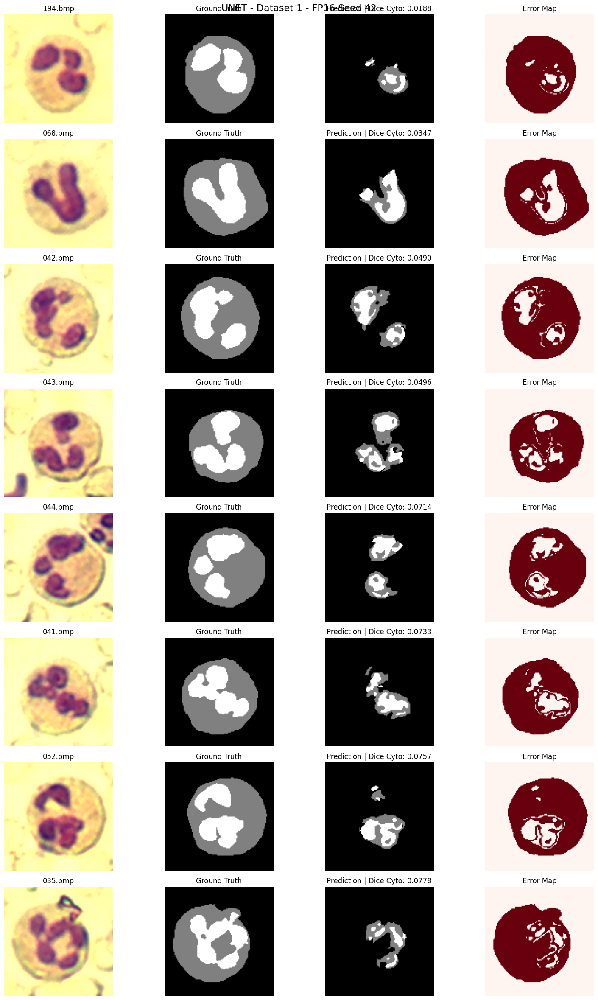

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16/gallery/worst8_unet_Dataset_1_fp16.png


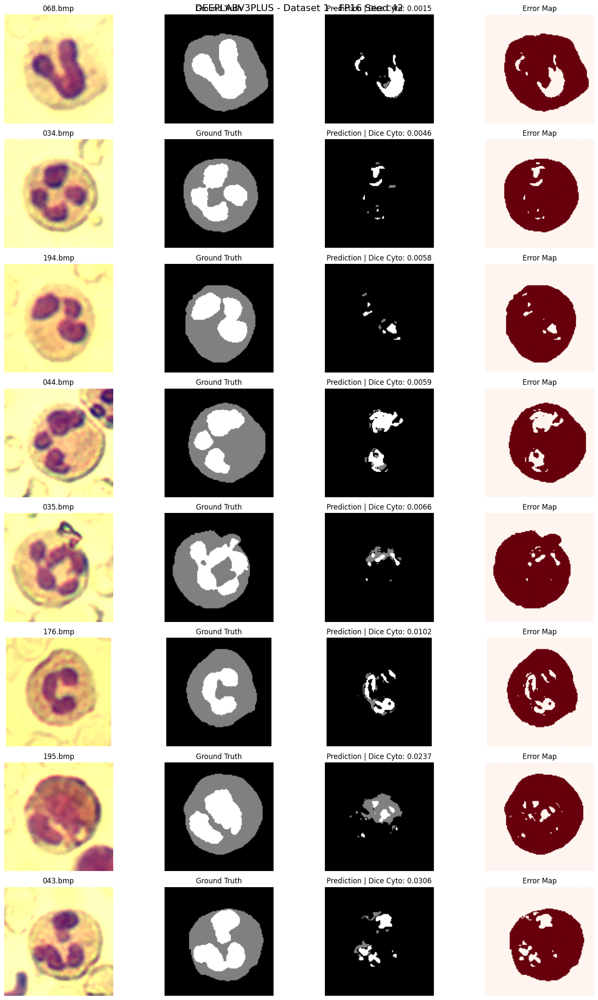

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16/gallery/worst8_deeplabv3plus_Dataset_1_fp16.png


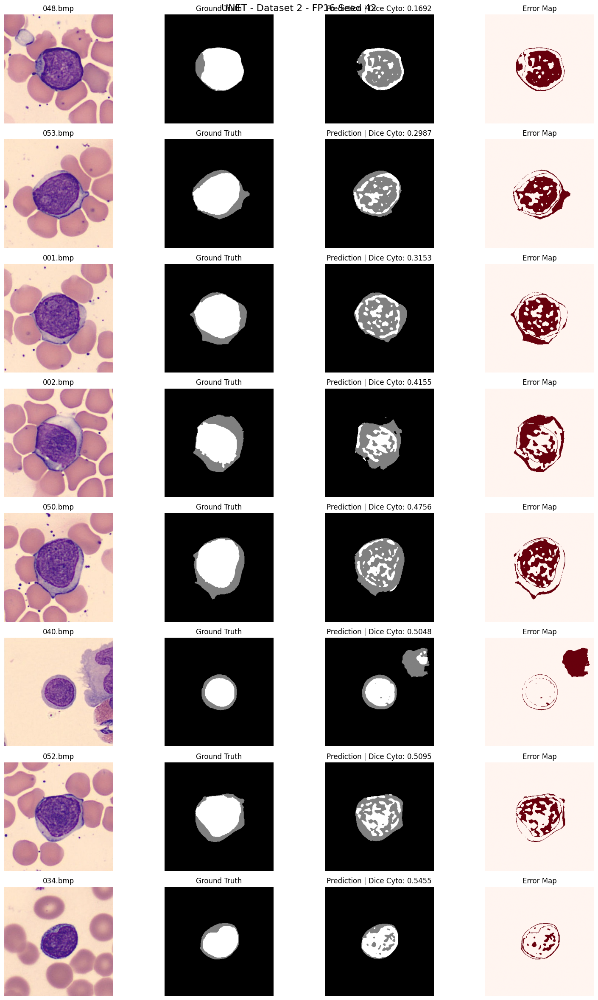

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16/gallery/worst8_unet_Dataset_2_fp16.png


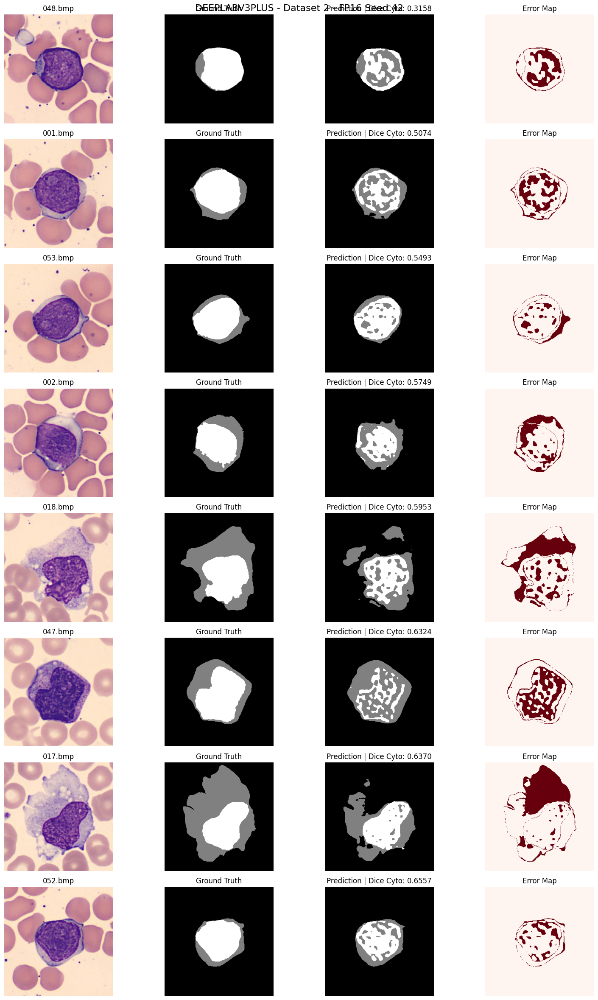

Tersimpan: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16/gallery/worst8_deeplabv3plus_Dataset_2_fp16.png


In [41]:
# CELL 30 — GALERI 8 KASUS TERBURUK FINAL FP16

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import gc

GALLERY_FINAL_DIR = ERROR_FINAL_DIR / "gallery"
GALLERY_FINAL_DIR.mkdir(parents=True, exist_ok=True)

def visualize_worst_fp16(model_name, dataset_name, seed=42):
    model = load_model(model_name, seed)
    model.eval()

    folder = dataset1 if dataset_name == "Dataset 1" else dataset2

    subset = df_worst_final[
        (df_worst_final["model"] == model_name) &
        (df_worst_final["dataset"] == dataset_name) &
        (df_worst_final["seed"] == seed)
    ].sort_values("dice_cyto")

    fig, axes = plt.subplots(
        len(subset), 4,
        figsize=(16, len(subset) * 3),
        squeeze=False
    )

    for i, (_, row) in enumerate(subset.iterrows()):
        img_path = folder / row["filename"]
        mask_path = img_path.with_suffix(".png")

        original = Image.open(img_path).convert("RGB")
        gt = convert_mask(
            np.asarray(Image.open(mask_path).convert("L"))
        )

        x = image_transform(original).unsqueeze(0)

        pred = original_metrics.predict_labels(
            model=model,
            x=x,
            out_hw=gt.shape,
            device=device_obj,
            amp=True
        )[0]

        metrics_check = original_metrics.per_image_metrics(
            pred, gt, with_hd95=True
        )

        # Pastikan visualisasi dan CSV memakai prediksi yang sama
        assert np.isclose(
            metrics_check["dice_cyto"],
            row["dice_cyto"],
            atol=1e-6,
            equal_nan=True
        ), f"Skor tidak cocok: {row['filename']}"

        error = (pred != gt).astype(np.uint8)

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(row["filename"])

        axes[i, 1].imshow(
            gt, cmap="gray", vmin=0, vmax=2
        )
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(
            pred, cmap="gray", vmin=0, vmax=2
        )
        axes[i, 2].set_title(
            f"Prediction | Dice Cyto: {row['dice_cyto']:.4f}"
        )

        axes[i, 3].imshow(
            error, cmap="Reds", vmin=0, vmax=1
        )
        axes[i, 3].set_title("Error Map")

        for ax in axes[i]:
            ax.axis("off")

    plt.suptitle(
        f"{model_name.upper()} - {dataset_name} - FP16 Seed {seed}",
        fontsize=16
    )

    plt.tight_layout()

    output = (
        GALLERY_FINAL_DIR /
        f"worst8_{model_name}_"
        f"{dataset_name.replace(' ', '_')}_fp16.png"
    )

    plt.savefig(
        output,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Tersimpan:", output)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for dataset_name in ["Dataset 1", "Dataset 2"]:
    for model_name in ["unet", "deeplabv3plus"]:
        visualize_worst_fp16(
            model_name,
            dataset_name,
            seed=42
        )

**hitung ulang frekuensi kesalahan FP16**

In [42]:
# CELL 31 — FREKUENSI KESALAHAN FINAL FP16

import pandas as pd
import numpy as np
import gc

error_rows_fp16 = []

for dataset_name, pairs in [
    ("Dataset 1", pairs_d1),
    ("Dataset 2", pairs_d2)
]:
    for model_name in ["unet", "deeplabv3plus"]:

        print("Memproses:", model_name, dataset_name)

        model = load_model(model_name, 42)
        model.eval()

        for img_path, mask_path in pairs:
            original = Image.open(img_path).convert("RGB")

            gt = convert_mask(
                np.asarray(Image.open(mask_path).convert("L"))
            )

            x = image_transform(original).unsqueeze(0)

            pred = original_metrics.predict_labels(
                model=model,
                x=x,
                out_hw=gt.shape,
                device=device_obj,
                amp=True
            )[0]

            # Fungsi berasal dari Cell 18
            errors = analyze_error_types(pred, gt)

            error_rows_fp16.append({
                "dataset": dataset_name,
                "model": model_name,
                "seed": 42,
                "filename": img_path.name,
                **errors
            })

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

df_errors_fp16 = pd.DataFrame(error_rows_fp16)

frequency_cols = [
    "severe_cytoplasm_miss",
    "nucleus_cytoplasm_confusion",
    "substantial_extra_foreground"
]

frequency_fp16 = (
    df_errors_fp16
    .groupby(["dataset", "model"])[frequency_cols]
    .sum()
    .astype(int)
)

print("\n=== FREKUENSI KESALAHAN FINAL FP16 ===")
display(frequency_fp16)

frequency_fp16.to_csv(
    ERROR_FINAL_DIR / "error_frequency_fp16.csv"
)

df_errors_fp16.to_csv(
    ERROR_FINAL_DIR / "error_detail_fp16.csv",
    index=False
)

assert len(df_errors_fp16) == 800

print("\nSelesai!")
print("Jumlah evaluasi:", len(df_errors_fp16))
print("Folder hasil:", ERROR_FINAL_DIR)

Memproses: unet Dataset 1
Memproses: deeplabv3plus Dataset 1
Memproses: unet Dataset 2
Memproses: deeplabv3plus Dataset 2

=== FREKUENSI KESALAHAN FINAL FP16 ===


severe_cytoplasm_miss  nucleus_cytoplasm_confusion  \
dataset   model                                                               
Dataset 1 deeplabv3plus                    129                          261   
          unet                             106                          213   
Dataset 2 deeplabv3plus                      1                           29   
          unet                               4                           45   

                         substantial_extra_foreground  
dataset   model                                        
Dataset 1 deeplabv3plus                             5  
          unet                                      5  
Dataset 2 deeplabv3plus                             0  
          unet                                      1


Selesai!
Jumlah evaluasi: 800
Folder hasil: /content/drive/MyDrive/PROYEK UAS DEEP LEARNING/results/external_zheng/final_verified/error_analysis_fp16
